## 1. Setup and imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import sys
import os
from itertools import product
from tqdm import tqdm
import math
from matplotlib.lines import Line2D


sys.path.append("./utils/")
from drc_utils import load_drc_data, bootstrap_DRC_fit

# Set up the plotting environment
sns.set(style="white", 
        font='Gill Sans')

## 2. Global settings

In [2]:
data_dir = os.getcwd()
file_name = "CS Drug List Data_C0_4_5_8.xlsx"
layout_file = os.path.join(data_dir, "plateLayout_CS.xlsx")

sheet_names_list = pd.ExcelFile(os.path.join(data_dir, file_name)).sheet_names

# Parameterise DRC fitting
n_bootstraps = 100
model = "ll4_log"
significance_level_ci = 0.95
from_scratch = True

# Define colors for replicates
replicate_palette = {'D1-m': sns.xkcd_rgb["dusty blue"], 'D2-m': sns.xkcd_rgb["steel grey"],
                        'R1-m': sns.xkcd_rgb["violet"], 'R2-m': sns.xkcd_rgb["teal green"], 'R3-m': sns.xkcd_rgb["orange"], 
                        'R4-m': sns.xkcd_rgb["plum"], 'R5-m': sns.xkcd_rgb["lightish blue"], 'R6-m': sns.xkcd_rgb["pink red"]}

# Define colors for drugs
drug_palette = {
    "osimertinib": sns.xkcd_rgb["purple"],
    "lapatinib": sns.xkcd_rgb["fuchsia"],
    "crizotinib": sns.xkcd_rgb["turquoise"],
    "alpelisib": sns.xkcd_rgb["deep green"],
    "dabrafenib": sns.xkcd_rgb["gold"],
    "everolimus": sns.xkcd_rgb["coral"],
    "ribociclib": sns.xkcd_rgb["dark pink"],
    "paclitaxel": sns.xkcd_rgb["bright blue"],
    "cisplatin": sns.xkcd_rgb["orange"],
    "pemetrexed": sns.xkcd_rgb["dark cyan"]
}

# Define markers for drugs
marker_palette = {
    "osimertinib": "o",
    "lapatinib": "s",
    "crizotinib": "^",
    "alpelisib": "d",
    "dabrafenib": "P",
    "everolimus": "*",
    "ribociclib": "X",
    "paclitaxel": "v",
    "cisplatin": "<",
    "pemetrexed": ">"
}

# Define treatment conditions
treatment_palette = {
    "DMSO": sns.xkcd_rgb["sea green"],  # Control (D1-m, D2-m)
    "Treated": sns.xkcd_rgb["purple"]   # Treated (R1-m to R6-m)
}


# Define colors for cycles
cycle_palette = {
    0: "black",
    4: sns.xkcd_rgb["very light pink"],
    5: sns.xkcd_rgb["pale pink"],
    8: sns.xkcd_rgb["pink"]             
}


## 3. Outliers detection

In [3]:
# ============================================================
# Drug mappings
# ============================================================
drug_info = {
    "1": ("osimertinib", 30),
    "2": ("lapatinib", 30),
    "3": ("crizotinib", 1),
    "4": ("alpelisib", 60),
    "5": ("dabrafenib", 50),
    "6": ("everolimus", 10),
    "7": ("ribociclib", 13),
    "8": ("paclitaxel", 5),
    "9": ("pemetrexed", 5),
    "10": ("cisplatin", 33),
}

# ============================================================
# Process each sheet
# ============================================================

tmp_list = []
for sheet in tqdm(sheet_names_list, desc="Processing Sheets"):
    sheet = sheet.strip()
    sheet_parts = sheet.split()

    # --------------------------------------------------------
    # Extract metadata from sheet name
    # --------------------------------------------------------
    cycle_id = int(sheet_parts[0][1:])
    replicate_name = (sheet_parts[1])
    experimental_arm = ("treatment" if "R" in replicate_name else "control")
    drug_id = [part for part in sheet_parts if "#" in part][0].replace("#", "").strip()
    drug_name, max_concentration = (drug_info[drug_id])

    # --------------------------------------------------------
    # Load and normalize plate data
    # --------------------------------------------------------
    tmp_df = load_drc_data(fname=os.path.join(data_dir, file_name),
        layout_file=layout_file,
        sheet_num=sheet,
        sheet_prefix=None,
        drug_names=[drug_name],
        max_concentrations=[max_concentration],
        cell_type_names=["H358"],
        machine="jinling_cs",
        negative_control="AB",
        drop_control=True,
        normalise_by="mean",
        detailed_output=False
    )


    # --------------------------------------------------------
    # Create cleaned viability column
    #
    # Original Viability remains unchanged so excluded points
    # can still be shown in QC plots.
    # --------------------------------------------------------
    tmp_df["Viability_cleaned"] = (tmp_df["Viability"])

    # ========================================================
    # C0 parental
    #
    # C0 is duplicated across replicate labels for downstream
    # plotting/comparison convenience.
    #
    # These are copies of the same parental C0 dataset and are
    # NOT independent biological replicates.
    # ========================================================
    if cycle_id == 0:
        for rep in ["D1-m", "D2-m", "R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"]:
            rep_df = (tmp_df.copy())
            rep_df["CycleId"] = 0
            rep_df["ReplicateName"] = (rep)
            rep_df["Replicate"] = int(rep[1])
            rep_df["ExperimentalArm"] = ("treatment" if "R" in rep else "control")
            rep_df["TreatmentTime"] = None
            tmp_list.append(rep_df)

    # ========================================================
    # C4 / C5 / C8
    # ========================================================
    else:
        tmp_df["CycleId"] = (cycle_id)
        tmp_df["ReplicateName"] = (replicate_name)
        tmp_df["Replicate"] = int(replicate_name[1])
        tmp_df["ExperimentalArm"] = (experimental_arm)
        tmp_list.append(tmp_df)


# ============================================================
# Combine all sheets
# ============================================================
results_df_all = pd.concat(tmp_list, axis=0)

# ============================================================
# Point-level outlier detection
#
# Rule 1A:
#   Original IQR-based rule.
#
# Rule 1B:
#   Additional consistency rule for technical triplicates.
#
# The triplicate rule is only used when:
#   - exactly 3 valid measurements are present
#   - the original IQR rule did not flag an outlier
#
# Triplicate rule:
#   - two measurements must agree within 20% of their mean
#   - the third measurement must differ from their mean
#     by at least 30%
#
# Detection remains based on Fluorescence_raw, consistent
# with the original notebook.
# ============================================================
def detect_outliers_iqr(data, pair_tolerance=0.20, outlier_gap=0.30):
    # --------------------------------------------------------
    # Preserve original index
    # --------------------------------------------------------
    data = pd.Series(data)
    flags = pd.Series(False, index=data.index)

    # Ignore missing values for calculation
    valid_data = (data.dropna())

    if valid_data.empty:
        return flags


    # ========================================================
    # Rule 1A: original IQR rule
    # ========================================================
    Q1 = valid_data.quantile(0.25, interpolation="nearest")
    Q3 = valid_data.quantile(0.75, interpolation="nearest")
    IQR = (Q3 - Q1)
    f = (3 / 1.35)

    if IQR != 0:
        iqr_flags = (np.abs((valid_data - valid_data.median()) / IQR) > f)
        flags.loc[iqr_flags.index] = iqr_flags

    # ========================================================
    # Rule 1B: triplicate-specific consistency rule
    #
    # This addresses the weakness of IQR when n = 3.
    # ========================================================
    if (len(valid_data) == 3 and not flags.loc[valid_data.index].any()):
        sorted_data = (valid_data.sort_values())
        low_idx = (sorted_data.index[0])
        mid_idx = (sorted_data.index[1])
        high_idx = (sorted_data.index[2])
        low = float(sorted_data.iloc[0])
        mid = float(sorted_data.iloc[1])
        high = float(sorted_data.iloc[2])
        candidate_outliers = []


        # ----------------------------------------------------
        # Test whether LOW + MID agree
        # and HIGH is discordant
        # ----------------------------------------------------
        lower_pair_mean = (low + mid) / 2

        if lower_pair_mean != 0:
            lower_pair_difference = (abs(low - mid) / abs(lower_pair_mean))
            high_difference = (abs(high - lower_pair_mean) / abs(lower_pair_mean))
            if (lower_pair_difference <= pair_tolerance and high_difference >= outlier_gap):
                candidate_outliers.append((high_idx, high_difference))

        # ----------------------------------------------------
        # Test whether MID + HIGH agree
        # and LOW is discordant
        # ----------------------------------------------------
        upper_pair_mean = (mid + high) / 2
        if upper_pair_mean != 0:
            upper_pair_difference = (abs(mid - high) / abs(upper_pair_mean))
            low_difference = (abs(low - upper_pair_mean) / abs(upper_pair_mean))
            if (upper_pair_difference <= pair_tolerance and low_difference >= outlier_gap):
                candidate_outliers.append((low_idx, low_difference))

        # ----------------------------------------------------
        # Flag at most ONE point in the triplicate.
        #
        # If both directions happen to satisfy the criteria,
        # use the more extreme candidate.
        # ----------------------------------------------------
        if len(candidate_outliers) > 0:
            outlier_idx = max(candidate_outliers, key=lambda x: x[1])[0]
            flags.loc[outlier_idx] = True
    return flags


# ============================================================
# Apply point-level outlier detection
#
# Applied separately within:
#
# ReplicateName × CycleId × Drug × DrugConcentration
# ============================================================
tmp_list = []

for _, df in results_df_all.groupby(["ReplicateName", "CycleId", "Drug", "DrugConcentration"]):
    df = (df.copy())
    df["IsOutlier"] = (detect_outliers_iqr(df["Fluorescence_raw"], pair_tolerance=0.20, outlier_gap=0.30))
    tmp_list.append(df)

results_df_all = pd.concat(tmp_list, axis=0)

# ============================================================
# Mask point-level outliers BEFORE rebound detection
#
# This is slightly different from the original workflow.
#
# It prevents a point already identified as an outlier from
# influencing the dose-level median used below.
# ============================================================
results_df_all["Viability_cleaned"] = (results_df_all["Viability_cleaned"].where(~results_df_all["IsOutlier"], np.nan))

# ============================================================
# Concentration-level rebound detection
# This is the original rebound rule.
#
# For each: ReplicateName × CycleId × Drug
# calculate median viability at each positive concentration.
#
# A concentration is flagged when:
#   current median - previous minimum > 15
# AND:
#   previous minimum < 80
# Point-level outliers identified above have already been
# removed from Viability_cleaned and therefore do not
# contribute to these medians.
# ============================================================
jump_threshold = 15
for _, df in results_df_all.groupby(["ReplicateName", "CycleId", "Drug"]):
    concentration_median = (df[df["DrugConcentration"] > 0].groupby("DrugConcentration")[ "Viability_cleaned"].median().sort_index())
    previous_minimum = (concentration_median.cummin().shift(1))
    rebound_concentrations = (concentration_median.index[(concentration_median - previous_minimum > jump_threshold) & (previous_minimum < 80)])
    mask = ((results_df_all["ReplicateName"] == df["ReplicateName"].iloc[0]) &(results_df_all["CycleId"] == df["CycleId"].iloc[0]) &
        (results_df_all["Drug"] == df["Drug"].iloc[0]) &
        (results_df_all["DrugConcentration"].isin(rebound_concentrations)))

    results_df_all.loc[mask, "IsOutlier"] = True

# ============================================================
# Apply final outlier mask
#
# This includes:
#
# 1. Original IQR-detected points
# 2. Triplicate-consistency outliers
# 3. Concentrations flagged by rebound detection
# ============================================================
results_df_all["Viability_cleaned"] = (results_df_all["Viability_cleaned"].where(~results_df_all["IsOutlier"], np.nan))

# ============================================================
# Save revised cleaned dataset
#
# Keep original CS_cleaned_c0458.csv unchanged while testing
# the revised outlier-detection method.
# ============================================================
results_df_all.to_csv(os.path.join(data_dir, "CS_cleaned_c0458_2.csv"))

# ============================================================
# Basic QC summary
# ============================================================
print("Total observations:", len(results_df_all))
print("Detected outliers:", int(results_df_all["IsOutlier"].sum()))
print("Percent outliers:", round(100 * results_df_all["IsOutlier"].mean(), 2), "%")

results_df_all.head()

Processing Sheets: 100%|██████████████████████| 182/182 [00:28<00:00,  6.42it/s]


Total observations: 9072
Detected outliers: 362
Percent outliers: 3.99 %


,RowId,ColumnId,Drug,WellId,DrugConcentration,Fluorescence_raw,CellType,Fluorescence_normalised,Viability,Machine,Viability_cleaned,CycleId,ReplicateName,Replicate,ExperimentalArm,TreatmentTime,IsOutlier
89,B,12,alpelisib,B12,0.000000,10194.0,H358,0.983459,98.345870,jinling_cs,98.345870,0,D1-m,1,control,None,False
90,C,12,alpelisib,C12,0.000000,10335.0,H358,0.998538,99.853838,jinling_cs,99.853838,0,D1-m,1,control,None,False
91,D,12,alpelisib,D12,0.000000,10517.0,H358,1.018003,101.800292,jinling_cs,101.800292,0,D1-m,1,control,None,False
81,B,11,alpelisib,B11,0.001016,10070.0,H358,0.970197,97.019714,jinling_cs,97.019714,0,D1-m,1,control,None,False
82,C,11,alpelisib,C11,0.001016,9985.0,H358,0.961107,96.110656,jinling_cs,96.110656,0,D1-m,1,control,None,False


## 5. Fit DRCs for all cell lines, cycles, and drugs

In [ ]:
csv_path = os.path.join(data_dir, "CS_cleaned_c0458_2.csv")
results_df_all = pd.read_csv(csv_path)
from_scratch = True
os.makedirs(os.path.join(data_dir, "drcs"), exist_ok=True)


# ============================================================
# Fit each ReplicateName × CycleId × Drug combination
# ============================================================
for i, curr_df in tqdm(
    list(results_df_all.groupby(["ReplicateName", "CycleId", "Drug"]))):
    replicate_name = (curr_df["ReplicateName"].iloc[0])
    cycle_id = (curr_df["CycleId"].iloc[0])
    drug_name = (curr_df["Drug"].iloc[0])

    # --------------------------------------------------------
    # Only use C0, C4, C5, and C8
    # --------------------------------------------------------
    if cycle_id not in [0, 4, 5, 8]:
        continue


    param_file = os.path.join(
        data_dir,
        "drcs",
        f"collateral_assays_params_"
        f"{replicate_name}_"
        f"{drug_name}_"
        f"{cycle_id}_"
        f"{n_bootstraps}.csv"
    )


    if ((not from_scratch) and os.path.exists(param_file)):
        continue


    # --------------------------------------------------------
    # Remove zero concentration and detected outliers
    #
    # Outliers have Viability_cleaned = NaN from Section 3
    # --------------------------------------------------------
    curr_df = curr_df[curr_df["DrugConcentration"] > 0].copy()
    curr_df = curr_df.dropna(subset=["DrugConcentration", "Viability_cleaned"])


    # --------------------------------------------------------
    # Skip dataset if no usable observations remain
    # --------------------------------------------------------
    if curr_df.empty:

        print(
            f"Skipping {replicate_name}, "
            f"C{cycle_id}, {drug_name}: "
            f"no usable data"
        )

        continue


    # --------------------------------------------------------
    # Basic information about dose-response range
    # --------------------------------------------------------
    max_concentration = (curr_df["DrugConcentration"].max())
    min_viability = (curr_df["Viability_cleaned"].min())


    # ========================================================
    # Default fitting parameters
    #
    # Parameter order:
    #
    # [e_max, e_min, b, ic50]
    # ========================================================
    lower_bound_list = [0, 0, 0, 0]
    upper_bound_list = [150, 100, 25, max_concentration * 5]

    # --------------------------------------------------------
    # Default initial estimates
    # --------------------------------------------------------
    p0 = [100, np.clip(min_viability, 0.1, 99), 1.0, max_concentration / 2]

    # ========================================================
    # Keep track of fitting rule
    # ========================================================
    fit_rule = "default"


    # ========================================================
    # 1. PEMETREXED
    # ========================================================
    if drug_name == "pemetrexed":
        lower_bound_list[2] = 0.5
        lower_bound_list[3] = 1e-4
        upper_bound_list[3] = 1e-1
        p0[2] = 1.0
        p0[3] = 1e-2
        fit_rule = (
            "pemetrexed all cycles: "
            "b >= 0.5; "
            "1e-4 <= IC50 <= 0.1 µM"
        )


    # ========================================================
    # 2. EVEROLIMUS
    # ========================================================
    elif drug_name == "everolimus":
        lower_bound_list[3] = 1e-6
        upper_bound_list[3] = 1e-1
        p0[3] = 1e-2
        fit_rule = (
            "everolimus all cycles: "
            "IC50 <= 0.1 µM"
        )


    # ========================================================
    # 3. RIBOCICLIB
    # ========================================================
    elif drug_name == "ribociclib":
        lower_bound_list[2] = 1.0
        lower_bound_list[3] = 1.0
        upper_bound_list[3] = (max_concentration * 5)
        p0[2] = 2.0
        p0[3] = max(max_concentration / 2, 1.5)
        fit_rule = (
            "ribociclib all cycles: "
            "b >= 1; "
            "IC50 >= 1 µM"
        )


    # ========================================================
    # 4. ALL OTHER DRUGS
    #
    # Keep original fitting logic.
    # ========================================================
    else:
        if min_viability > 50:
            lower_bound_list[3] = (max_concentration * 0.8)
            p0[3] = (max_concentration)
            fit_rule = (
                "default; min viability > 50: "
                "IC50 lower bound = 0.8 × max dose"
            )


    # ========================================================
    # A. PEMETREXED C4 R2-m
    # ========================================================
    if (drug_name == "pemetrexed" and replicate_name == "R2-m" and cycle_id == 4):
        upper_bound_list[1] = 150
        fit_rule += (
            "; postdoc override: "
            "C4 R2-m e_min upper bound = 150"
        )


    # ========================================================
    # B. PEMETREXED C8 R5-m
    # ========================================================
    if (
        drug_name == "pemetrexed"
        and replicate_name == "R5-m"
        and cycle_id == 8
    ):

        lower_bound_list[3] = 1e-2

        fit_rule += (
            "; postdoc override: "
            "C8 R5-m IC50 lower bound = 1e-2 µM"
        )


    # ========================================================
    # C. CRIZOTINIB C4 R6-m
    # ========================================================
    if (
        drug_name == "crizotinib"
        and replicate_name == "R6-m"
        and cycle_id == 4
    ):

        lower_bound_list[3] = 1e-1

        fit_rule += (
            "; postdoc override: "
            "C4 R6-m IC50 lower bound = 1e-1 µM"
        )

    # ========================================================
    # Validate bounds and starting values
    # ========================================================
    lower_bounds = np.asarray(lower_bound_list, dtype=float)
    upper_bounds = np.asarray(upper_bound_list, dtype=float)
    p0 = np.asarray(p0, dtype=float)

    # --------------------------------------------------------
    # Make sure bounds themselves are valid
    # --------------------------------------------------------
    if np.any(lower_bounds >= upper_bounds):

        print("\nINVALID BOUNDS")
        print(replicate_name, cycle_id, drug_name)
        print("Lower:", lower_bounds)
        print("Upper:", upper_bounds)

        raise ValueError(
            "Each lower bound must be "
            "strictly smaller than its upper bound."
        )


    # --------------------------------------------------------
    # Ensure initial guesses are inside bounds
    #
    # This changes ONLY starting values,
    # not fitting bounds.
    # --------------------------------------------------------
    eps = 1e-6
    p0 = np.clip(p0, lower_bounds + eps, upper_bounds - eps)

    # ========================================================
    # Print current fit
    # ========================================================
    print(
        f"{replicate_name}  "
        f"C{cycle_id}  "
        f"{drug_name}"
    )


    print(
        f"  min viability = "
        f"{min_viability:.2f}"
    )


    print(
        f"  max concentration = "
        f"{max_concentration:.4g}"
    )


    print(
        f"  fitting rule = "
        f"{fit_rule}"
    )


    print(
        "  lower bounds =",
        lower_bounds
    )


    print(
        "  p0           =",
        p0
    )


    print(
        "  upper bounds =",
        upper_bounds
    )


    # ========================================================
    # Fit dose-response curve + bootstrap
    # ========================================================
    (param_df, prediction_df, param_df_bootstrap, prediction_df_bootstrap) = bootstrap_DRC_fit(data_df=curr_df, model="ll4_log",
        x="DrugConcentration",
        y="Viability_cleaned",
        bounds_list=(lower_bounds, upper_bounds),
        p0=p0,
        n_boot=n_bootstraps,
        significance_level_ci=significance_level_ci,
        return_bootstrap=True,
        show_progress=False
    )


    # ========================================================
    # Annotate fitted results
    # ========================================================
    for x in [param_df, prediction_df, param_df_bootstrap, prediction_df_bootstrap]:
        x["ReplicateName"] = (replicate_name)
        x["CycleId"] = (cycle_id)
        x["Drug"] = (drug_name)
    # ========================================================
    # Save individual DRC results
    # ========================================================
    for df, name in zip([param_df, prediction_df, param_df_bootstrap, prediction_df_bootstrap],
        ["params", "fit", "params_bootstrap", "fit_bootstrap"]):
        df.to_csv(os.path.join(data_dir, "drcs", f"collateral_assays_" f"{name}_" f"{replicate_name}_" f"{drug_name}_" f"{cycle_id}_" f"{n_bootstraps}.csv"))

  0%|                                                   | 0/252 [00:00<?, ?it/s]

D1-m  C0  alpelisib
  min viability = 19.64
  max concentration = 60
  fitting rule = default
  lower bounds = [0. 0. 0. 0.]
  p0           = [100.          19.64279348   1.          30.        ]
  upper bounds = [150. 100.  25. 300.]


  0%|▏                                          | 1/252 [00:02<11:27,  2.74s/it]

D1-m  C0  cisplatin
  min viability = 3.88
  max concentration = 33
  fitting rule = default
  lower bounds = [0. 0. 0. 0.]
  p0           = [100.           3.87539858   1.          16.5       ]
  upper bounds = [150. 100.  25. 165.]


  1%|▎                                          | 2/252 [00:05<10:59,  2.64s/it]

...

D1-m  C4  lapatinib
  min viability = -0.41
  max concentration = 30
  fitting rule = default
  lower bounds = [0. 0. 0. 0.]
  p0           = [100.    0.1   1.   15. ]
  upper bounds = [150. 100.  25. 150.]


  6%|██▋                                       | 16/252 [00:55<15:06,  3.84s/it]

D1-m  C4  osimertinib
  min viability = 0.08
  max concentration = 30
  fitting rule = default
  lower bounds = [0. 0. 0. 0.]
  p0           = [100.    0.1   1.   15. ]
  upper bounds = [150. 100.  25. 150.]


  7%|██▊                                       | 17/252 [00:59<14:16,  3.64s/it]

D1-m  C4  paclitaxel
  min viability = 14.41
  max concentration = 5
  fitting rule = default
  lower bounds = [0. 0. 0. 0.]
  p0           = [100.          14.40974284   1.           2.5       ]
  upper bounds = [150. 100.  25.  25.]


## Concatenate results across all fitted datasets

In [4]:
for name in ["params", "fit", "params_bootstrap", "fit_bootstrap"]:
    tmp_list = []
    for file in os.listdir(os.path.join(data_dir, "drcs")):
        if ((name in file) and (name + "_b" not in file) and file.endswith(f"_{n_bootstraps}.csv")):
            tmp_list.append(pd.read_csv(os.path.join(data_dir, "drcs", file), index_col=0))
    # --------------------------------------------------------
    # Make sure matching files were found
    # --------------------------------------------------------
    if len(tmp_list) == 0:
        print(f"No files found for: {name}")
        continue

    # --------------------------------------------------------
    # Concatenate
    # --------------------------------------------------------
    combined_df = pd.concat(tmp_list, axis=0, ignore_index=False)


    # --------------------------------------------------------
    # Save revised analysis with _3 suffix
    # --------------------------------------------------------
    output_file = os.path.join(data_dir, f"CS_drc_{name}_c0458_3.csv")
    combined_df.to_csv(output_file)
    print(
        f"Saved CS_drc_{name}_c0458_3.csv: "
        f"{combined_df.shape[0]} rows"
    )


# ============================================================
# Load the newly combined collateral-screening DRC results
# ============================================================
params_df = pd.read_csv(os.path.join(data_dir, "CS_drc_params_c0458_3.csv"), index_col=0)
fit_df = pd.read_csv(os.path.join(data_dir, "CS_drc_fit_c0458_3.csv"), index_col=0)
params_df_bootstraps = pd.read_csv(os.path.join(data_dir, "CS_drc_params_bootstrap_c0458_3.csv"), index_col=0)
fit_df_bootstraps = pd.read_csv(os.path.join(data_dir, "CS_drc_fit_bootstrap_c0458_3.csv"), index_col=0)

Saved CS_drc_params_c0458_3.csv: 1260 rows
Saved CS_drc_fit_c0458_3.csv: 2718 rows
Saved CS_drc_params_bootstrap_c0458_3.csv: 125455 rows
Saved CS_drc_fit_bootstrap_c0458_3.csv: 270601 rows


In [5]:
# ============================================================
# Load dose-response fitting results
# ============================================================
params_df = pd.read_csv(os.path.join(data_dir, "CS_drc_params_c0458_3.csv"), index_col=0)
fit_df = pd.read_csv(os.path.join(data_dir, "CS_drc_fit_c0458_3.csv"), index_col=0)
params_df_bootstraps = pd.read_csv(os.path.join(data_dir, "CS_drc_params_bootstrap_c0458_3.csv"), index_col=0)
fit_df_bootstraps = pd.read_csv(os.path.join(data_dir, "CS_drc_fit_bootstrap_c0458_3.csv"), index_col=0)


# ============================================================
# Conditions to analyze
# ============================================================
cycles = [0, 4, 5, 8]
resistant_replicates = ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"]

# ============================================================
# Control reference for bootstrap 95% CI
# Include:
#   1. Parental C0 once -> represented by D1-m C0
#   2. D1-m C8
#   3. D2-m C8
#
# D2-m C0 is NOT included because C0 was duplicated across
# replicate labels during preprocessing.
# ============================================================


# ============================================================
# Annotate CI non-overlap for each drug
# ===========================================================
params_df["StatDifferent"] = False


# ------------------------------------------------------------
# Do not include AUC here yet.
#
# Current AUC is calculated from fitted DRCs, and this is the
# metric that will be revised separately.
# ------------------------------------------------------------
for parameter in ["ic50", "e_max", "e_min", "b"]:
    for drug_name in (params_df["Drug"].dropna().unique()):

        # ====================================================
        # Pooled control bootstrap distribution
        # One parental C0: D1-m C0
        # C8 controls:
        #   D1-m C8
        #   D2-m C8
        # ====================================================
        control_values = (params_df_bootstraps.loc[(
                    # -----------------------------------------
                    # One parental C0 bootstrap distribution
                    # -----------------------------------------
                    ((params_df_bootstraps["ReplicateName"] == "D1-m") &
                        (params_df_bootstraps["CycleId"] == 0)) |

                    # -----------------------------------------
                    # C8 DMSO controls
                    # -----------------------------------------
                    ((params_df_bootstraps["ReplicateName"].isin(["D1-m", "D2-m"])) &
                        (params_df_bootstraps["CycleId"] == 8))) &
                (params_df_bootstraps["Parameter"] == parameter) & (params_df_bootstraps["Drug"] == drug_name), "Value"].dropna())

        if control_values.empty:
            continue
        # ====================================================
        # 95% CI of pooled control bootstrap distribution
        # ====================================================
        lower_CI = (control_values.quantile((1 - significance_level_ci) / 2))
        upper_CI = (control_values.quantile((1 + significance_level_ci) / 2))

        # ====================================================
        # Resistant bootstrap distributions
        #
        # Compare R1-m–R6-m at C4, C5, and C8.
        #
        # C5 naturally exists only where data are available.
        # ====================================================
        condition_df = (params_df_bootstraps[(params_df_bootstraps["Parameter"] == parameter) &
                (params_df_bootstraps["Drug"] == drug_name) &
                (params_df_bootstraps["ReplicateName"].isin(resistant_replicates)) &
                (params_df_bootstraps["CycleId"].isin([4, 5, 8]))].copy())

        for (replicate_name, cycle_id), curr_df in condition_df.groupby(["ReplicateName", "CycleId"]):
            curr_values = (curr_df["Value"].dropna())
            if curr_values.empty:
                continue


            # -----------------------------------------------
            # 95% CI for current resistant condition
            # -----------------------------------------------
            curr_lower = (curr_values.quantile((1 - significance_level_ci) / 2))
            curr_upper = (curr_values.quantile((1 + significance_level_ci) / 2))

            # -----------------------------------------------
            # Does current CI completely avoid control CI?
            # -----------------------------------------------
            no_overlap = ((curr_upper < lower_CI) or (curr_lower > upper_CI))

            # -----------------------------------------------
            # Store result
            # -----------------------------------------------
            params_df.loc[(params_df["ReplicateName"]  == replicate_name) &
                (params_df["CycleId"] == cycle_id) &
                (params_df["Parameter"] == parameter) &
                (params_df["Drug"] == drug_name), "StatDifferent"] = bool(no_overlap)

# ============================================================
# Save updated results
# ============================================================
params_df.to_csv(os.path.join(data_dir, "CS_drc_params_c0458_3.csv"))

print(
    "Updated dose-response metrics saved to "
    "`CS_drc_params_c0458_3.csv`"
)

Updated dose-response metrics saved to `CS_drc_params_c0458_3.csv`


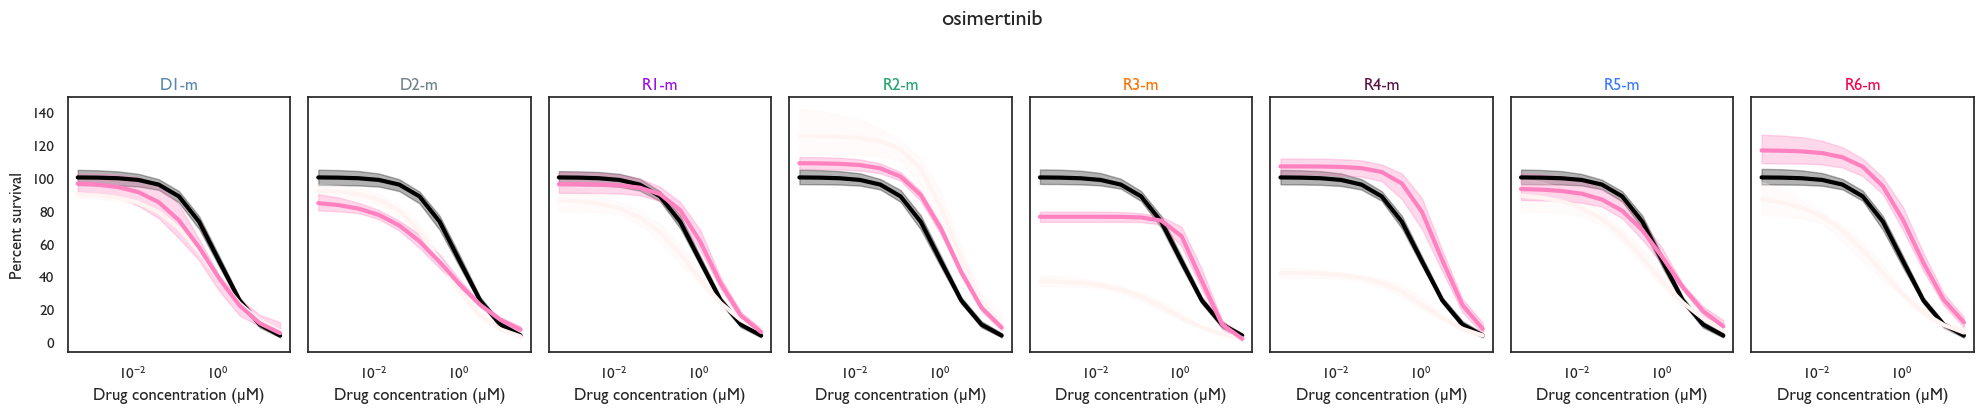

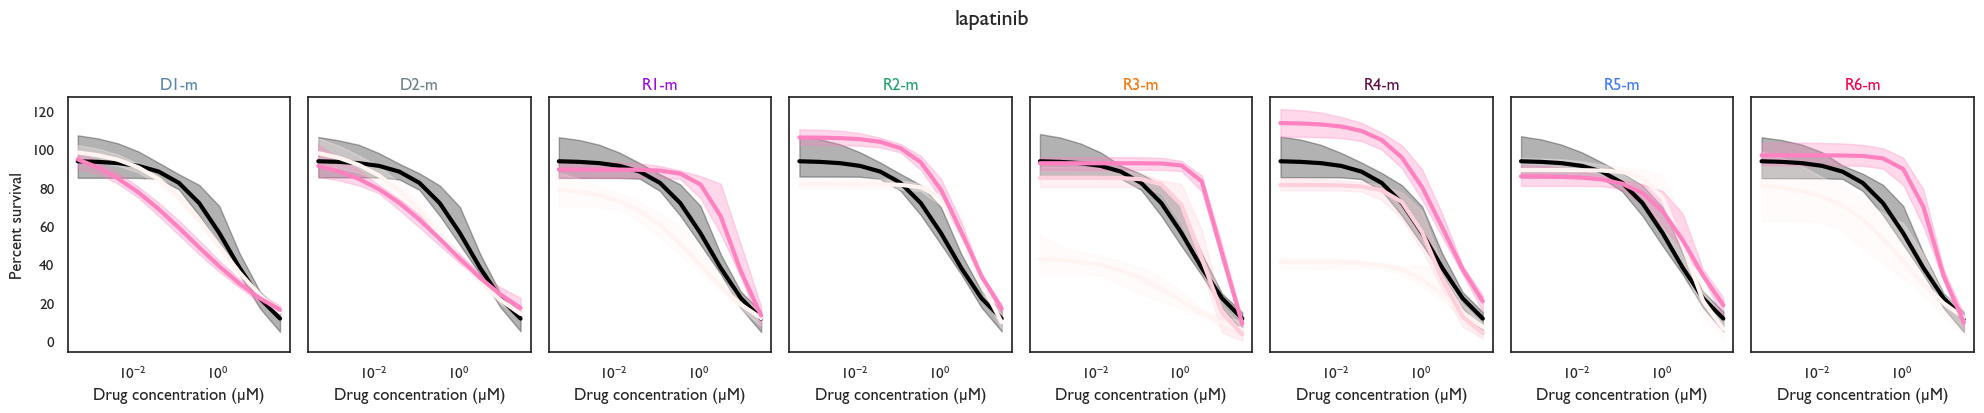

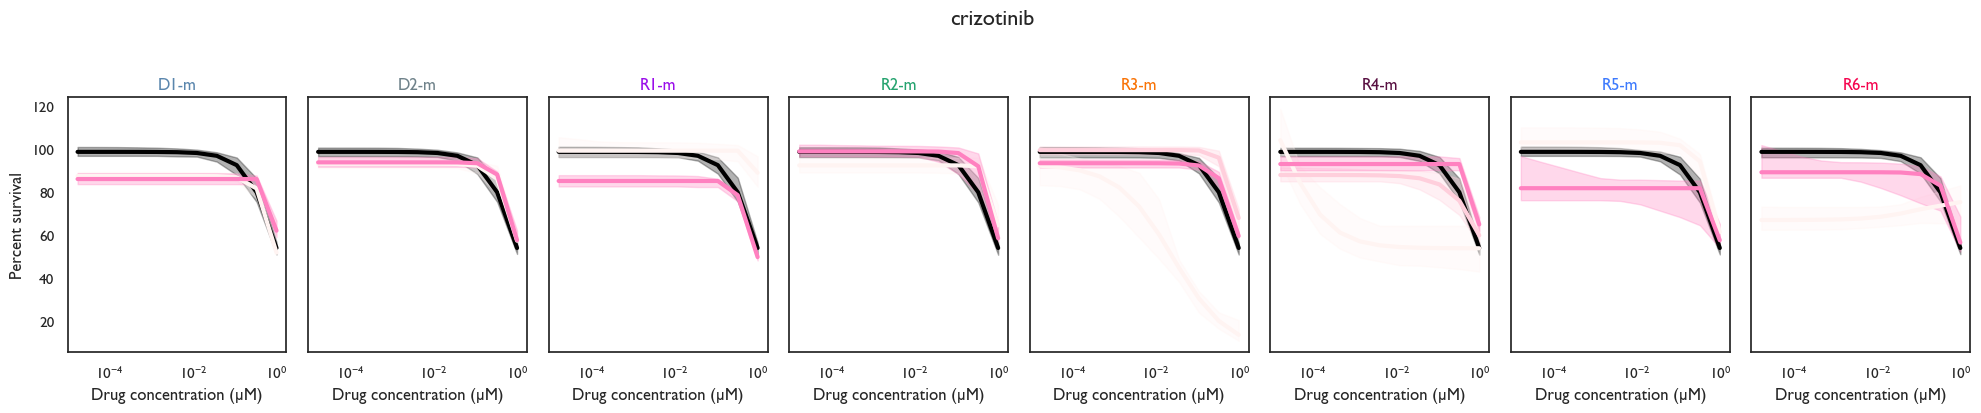

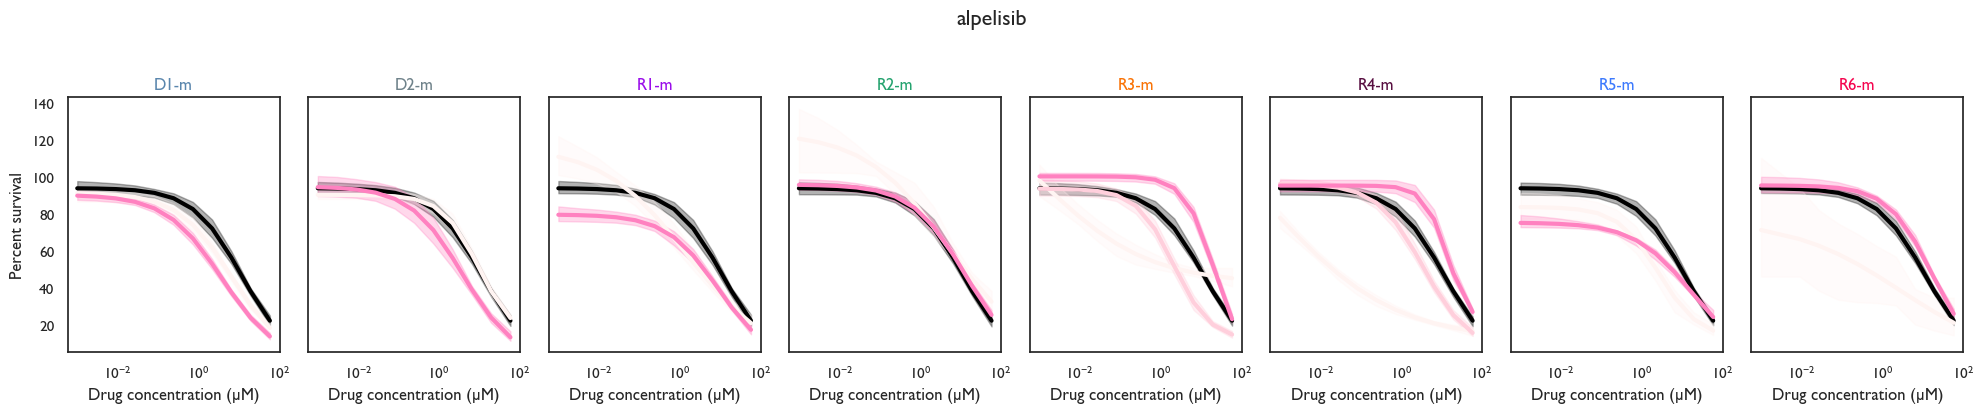

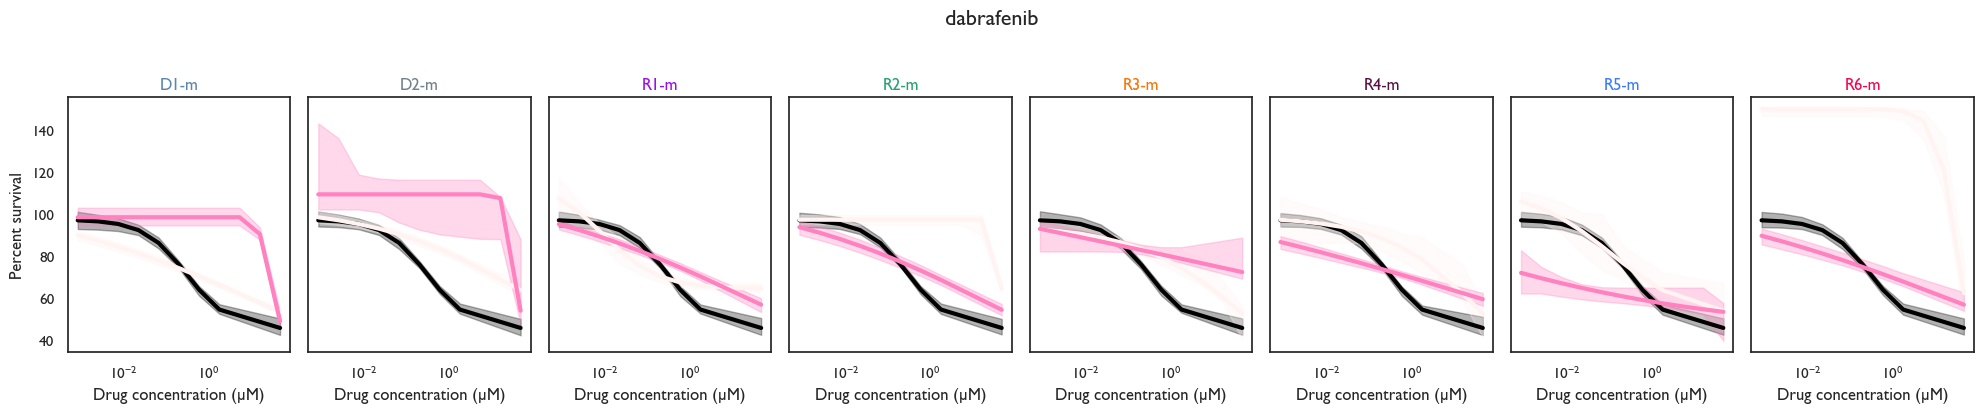

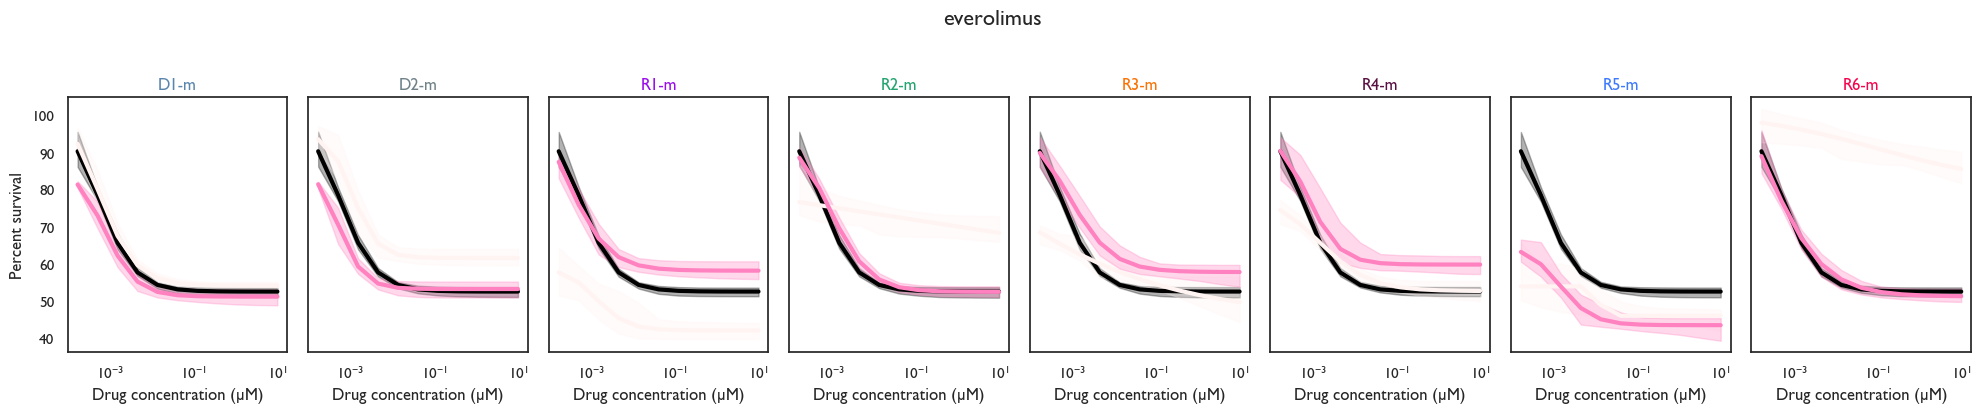

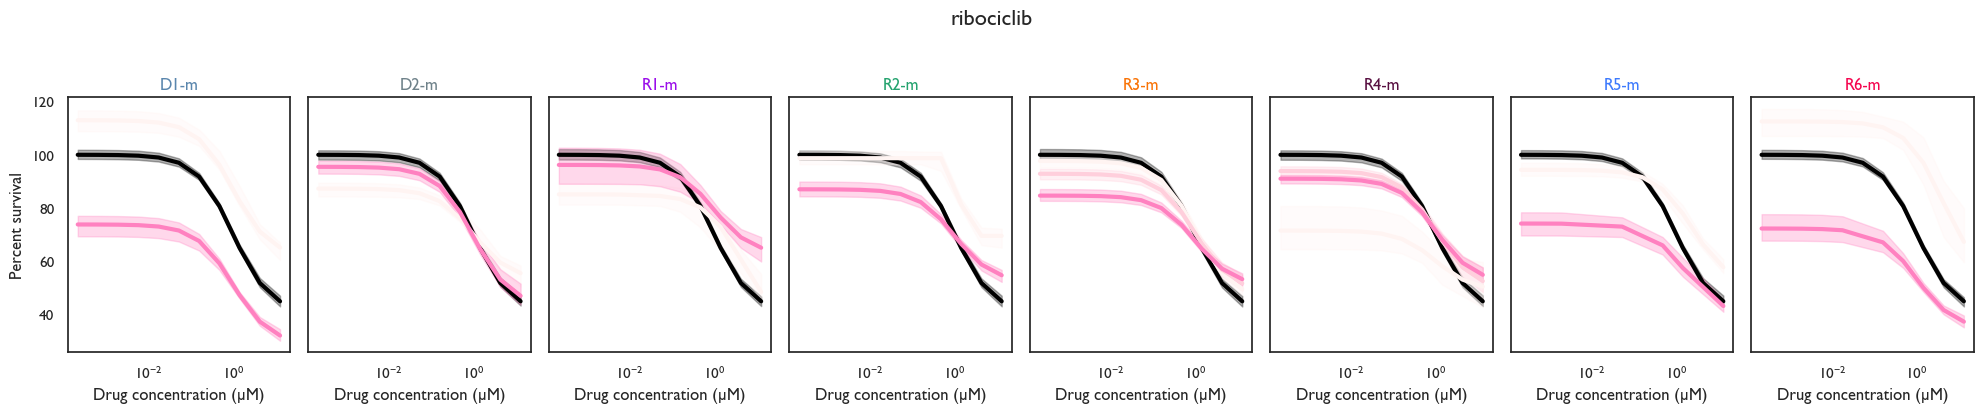

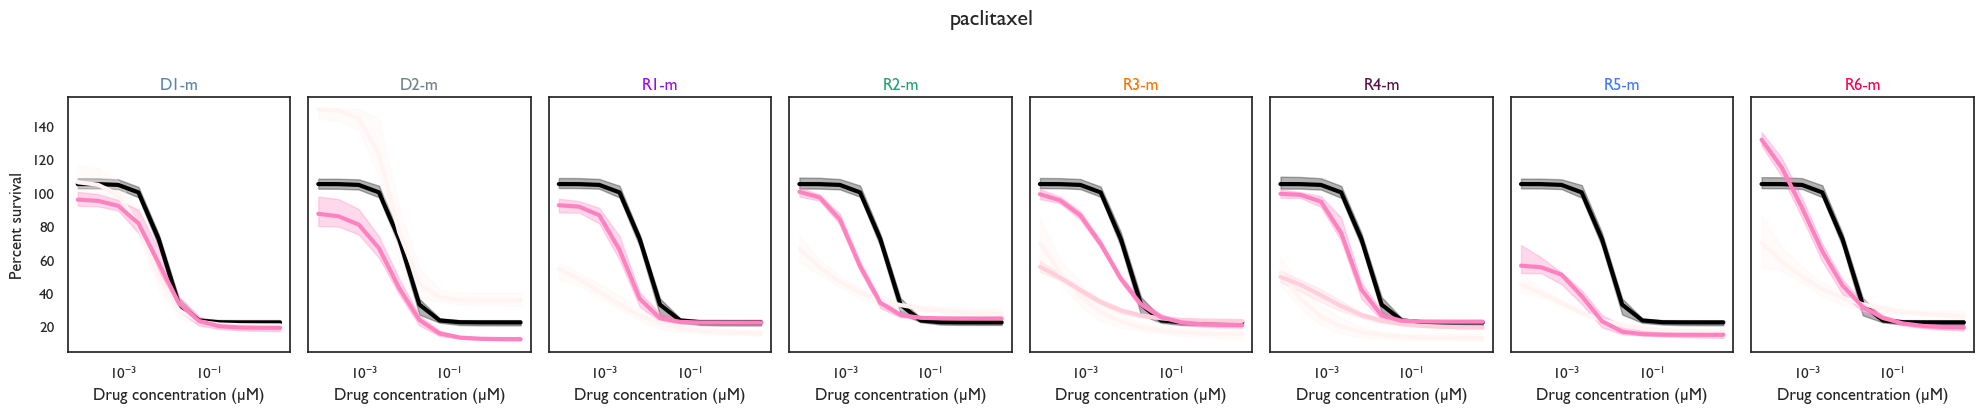

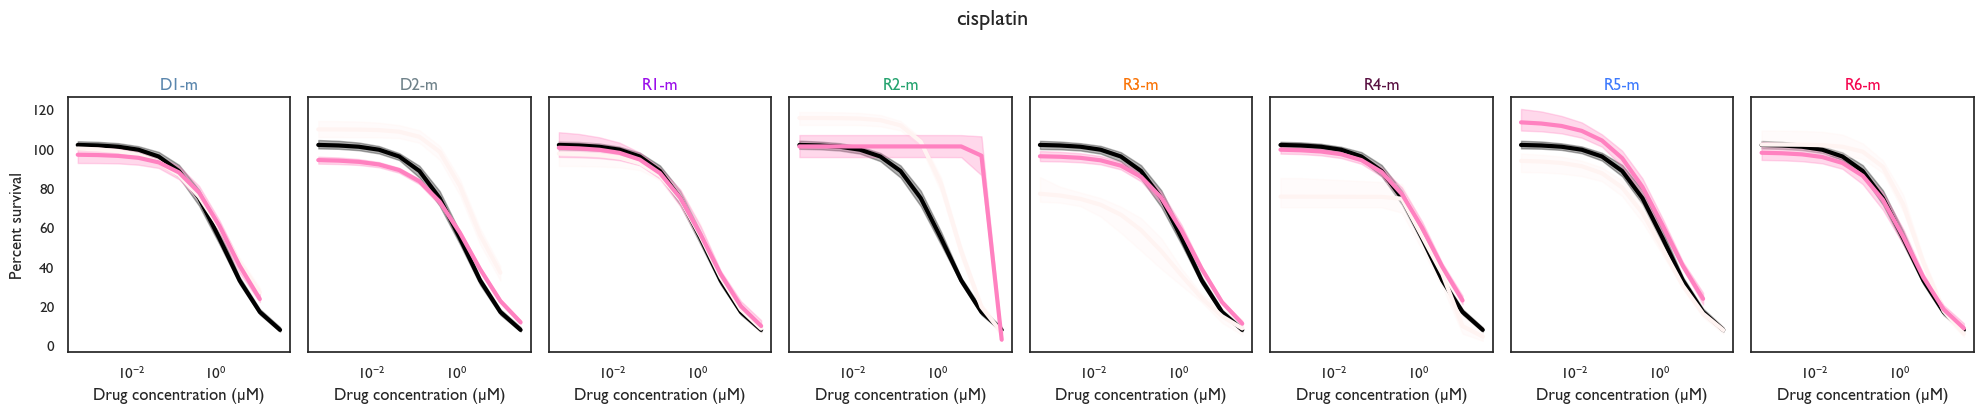

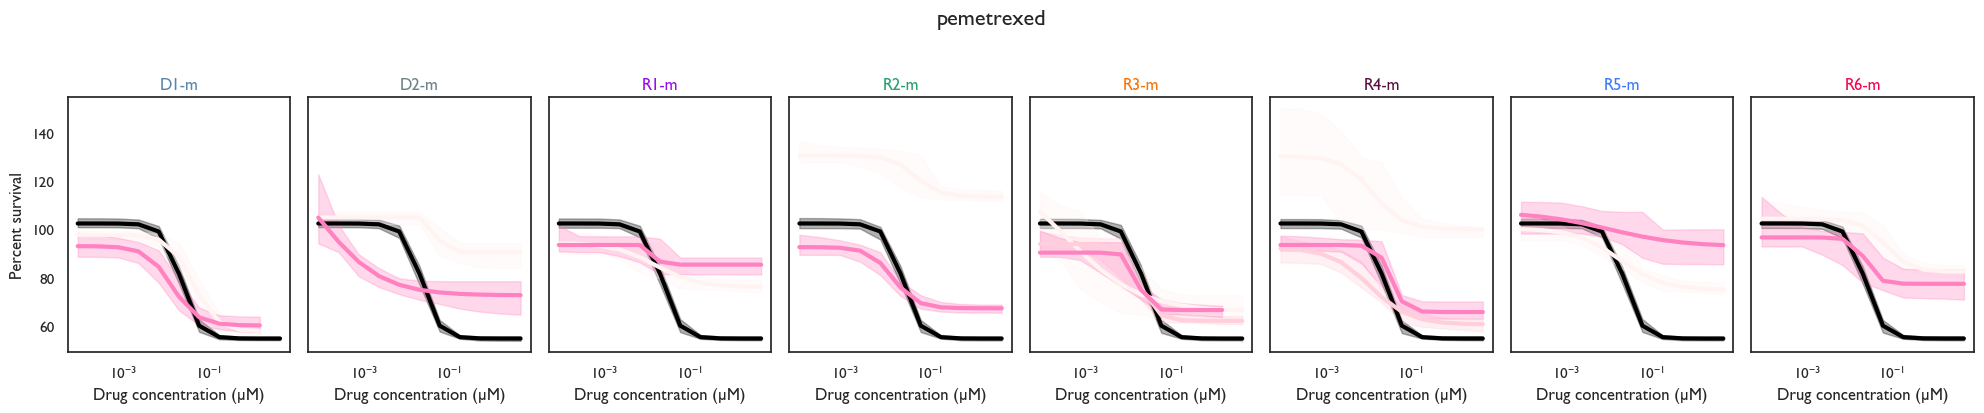

In [6]:
# ============================================================
# Load fitted DRC results
# ============================================================
fit_df = pd.read_csv(os.path.join(data_dir, "CS_drc_fit_c0458_3.csv"), index_col=0)

# ============================================================
# Drugs, cycles, and replicates to display
# ============================================================
drugs = ["osimertinib", "lapatinib", "crizotinib", "alpelisib", "dabrafenib", "everolimus", "ribociclib", "paclitaxel", "cisplatin", "pemetrexed"]
cycles = [0, 4, 5, 8]
replicates = ["D1-m", "D2-m", "R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"]

# ============================================================
# Loop through each drug and create one overview figure
# ============================================================
for drug_name in drugs:
    fig, ax_list = plt.subplots(1, len(replicates), sharex=True, sharey=True, figsize=(20, 4))

    # --------------------------------------------------------
    # One panel per replicate
    # --------------------------------------------------------
    for i, replicate_name in enumerate(replicates):
        ax = ax_list[i]

        # ----------------------------------------------------
        # Get fitted curves for this replicate + drug
        # ----------------------------------------------------
        prediction_df = fit_df[(fit_df["ReplicateName"] == replicate_name) &
            (fit_df["Drug"] == drug_name) &
            (fit_df["CycleId"].isin(cycles))].copy()

        if prediction_df.empty:
            ax.set_visible(False)
            continue

        # ----------------------------------------------------
        # Plot fitted DRCs
        # ----------------------------------------------------
        sns.lineplot(
            x="DrugConcentration",
            y="Viability_cleaned",
            hue="CycleId",
            hue_order=cycles,
            linewidth=3,
            palette=cycle_palette,
            estimator=None,
            data=prediction_df,
            legend=False,
            ax=ax
        )

        # ----------------------------------------------------
        # Plot confidence intervals
        # ----------------------------------------------------
        for cycle_id in cycles:
            curr_df = prediction_df[prediction_df["CycleId"] == cycle_id].copy()

            if curr_df.empty:
                continue

            curr_df = curr_df.sort_values("DrugConcentration")
            ax.fill_between(curr_df["DrugConcentration"], curr_df["LowerCI"], curr_df["UpperCI"], color=cycle_palette[cycle_id], alpha=0.3)

        # ----------------------------------------------------
        # Axis labels and panel title
        # ----------------------------------------------------
        ax.set_xscale("log")
        ax.set_xlabel("Drug concentration (µM)")
        ax.set_ylabel("Percent survival")
        ax.set_title(replicate_name, color=replicate_palette[replicate_name])

    # --------------------------------------------------------
    # Figure title
    # --------------------------------------------------------
    fig.suptitle(drug_name, fontsize=16, y=1.03)

    # --------------------------------------------------------
    # Save figure
    # --------------------------------------------------------
    plt.tight_layout()
    os.makedirs(os.path.join(data_dir, "figures"), exist_ok=True)
    plt.savefig(os.path.join(data_dir, "figures", f"CS_drc_overview_" f"{drug_name}_c0458_3.pdf"), bbox_inches="tight")
    plt.show()

## Longitudinal collateral-screening DRC figures
Revised analysis:
- cleaned data: *_c0458_2
- fitted results: *_c0458_2

Control reference for IC50 95% CI:
parental C0 bootstrap distribution + D1-m C8 + D2-m C8

IMPORTANT: StatDifferent was already calculated and saved in the previous section. Do NOT recalculate it again here.
NEW: Add D1-m and D2-m C4/C8 DRCs to the right-hand side for control-fit QC.
The left IC50 panel remains resistant R1-m–R6-m only.

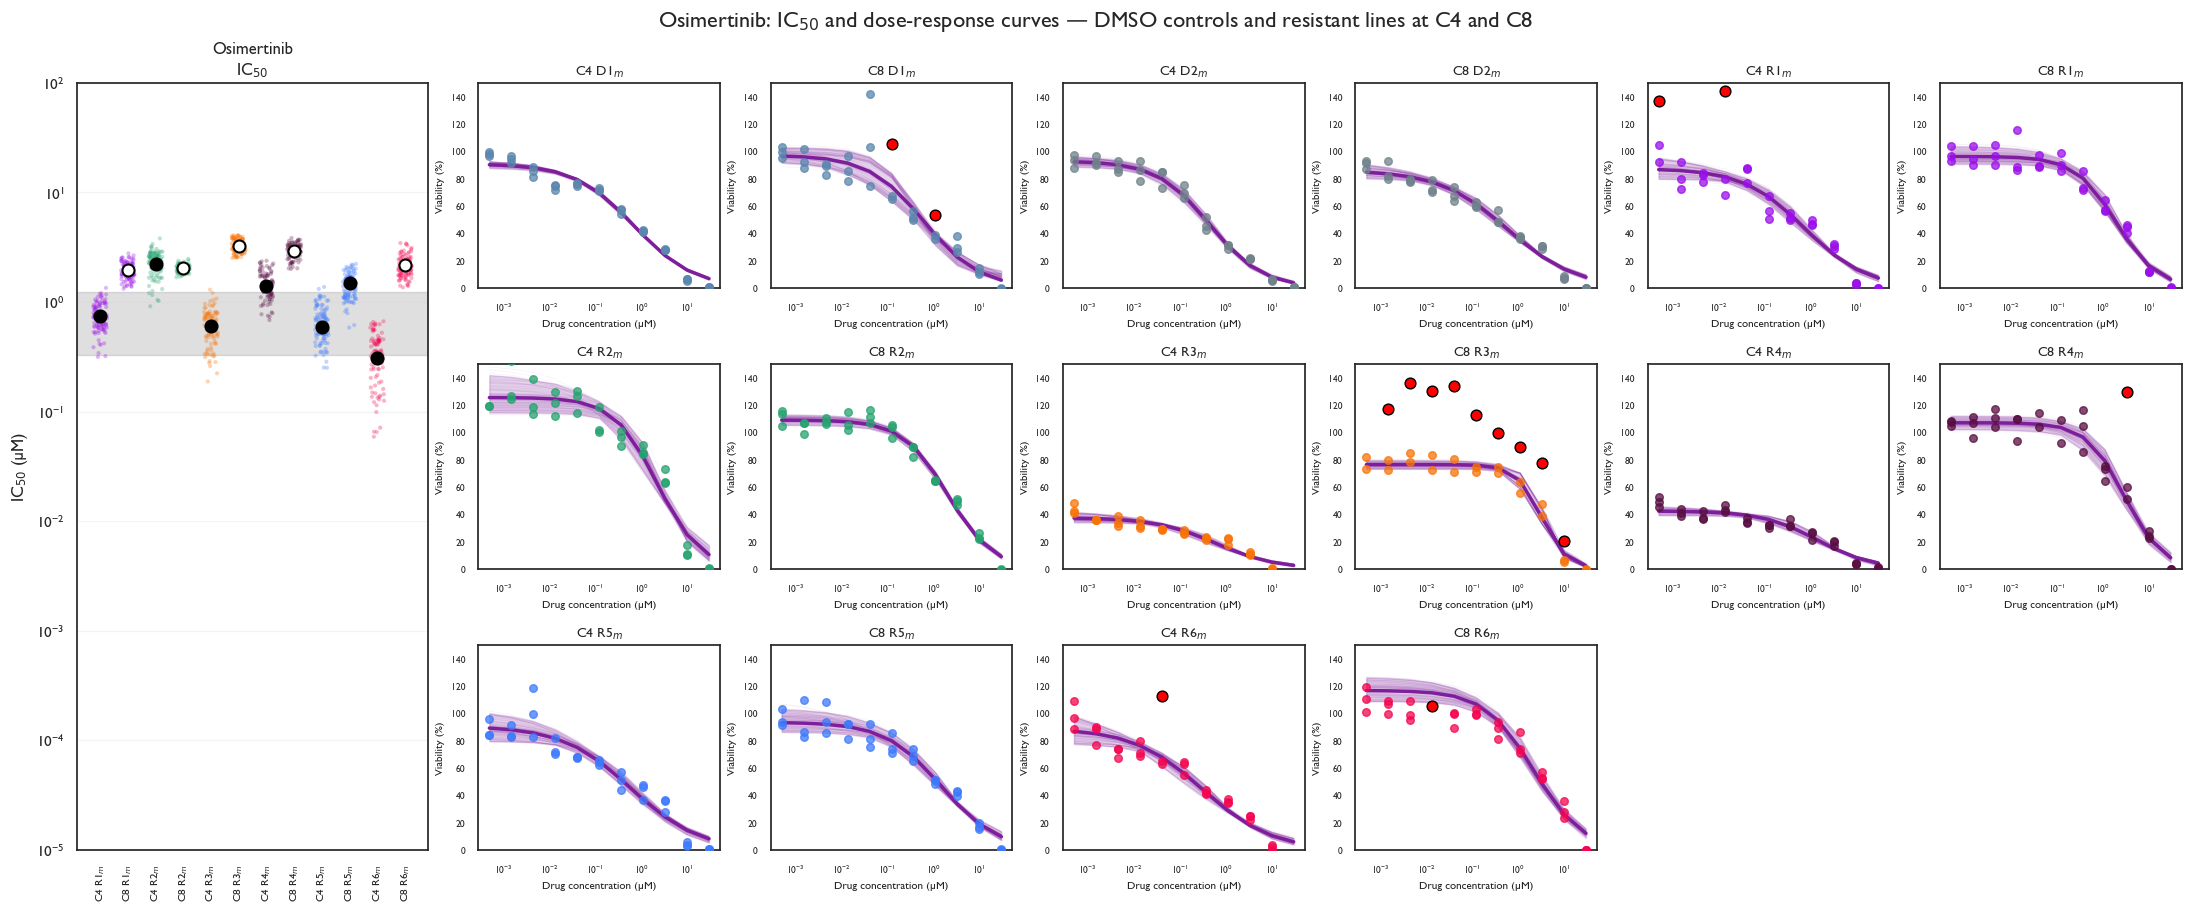

osimertinib: 16 DRC panels plotted (including 4 D1/D2 control panels).
Saved: CS_drc_osimertinib_C4_C8_with_controls_ic50_drcs_3.pdf


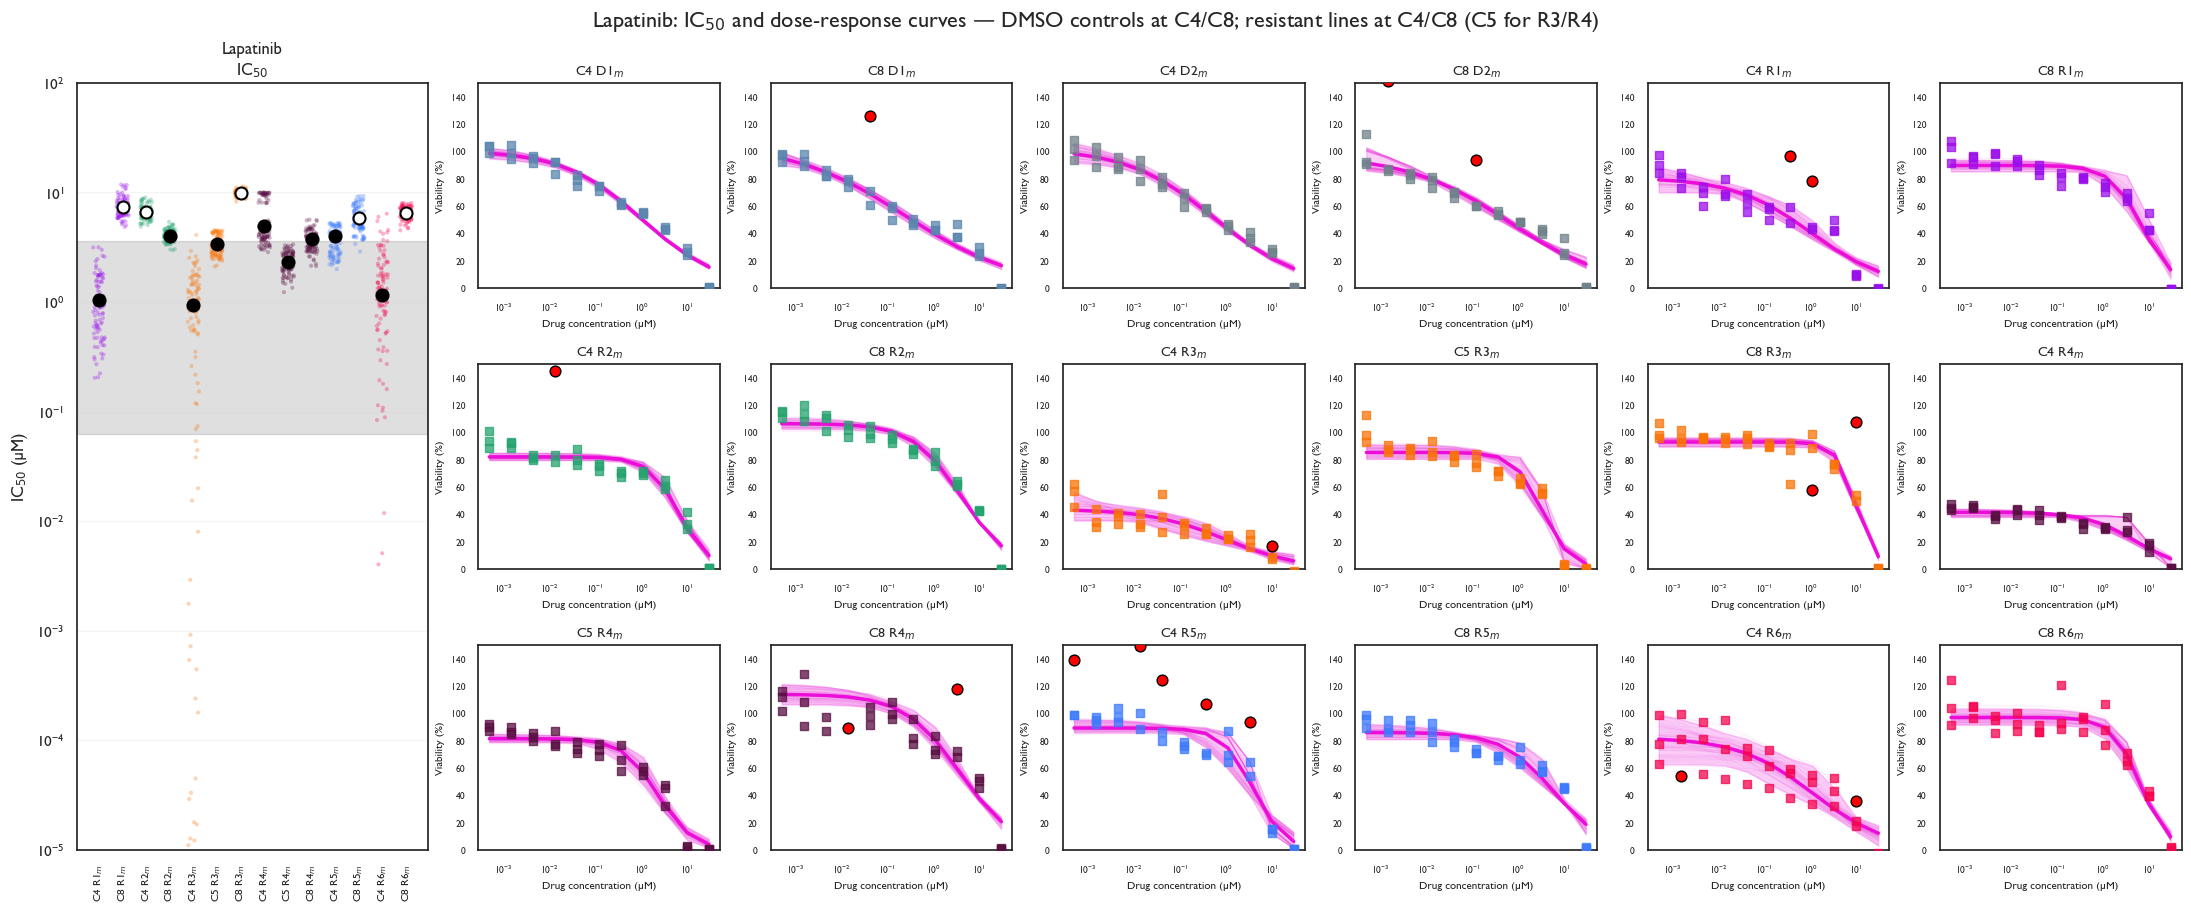

lapatinib: 18 DRC panels plotted (including 4 D1/D2 control panels).
Saved: CS_drc_lapatinib_C4_C5_C8_with_controls_ic50_drcs_3.pdf


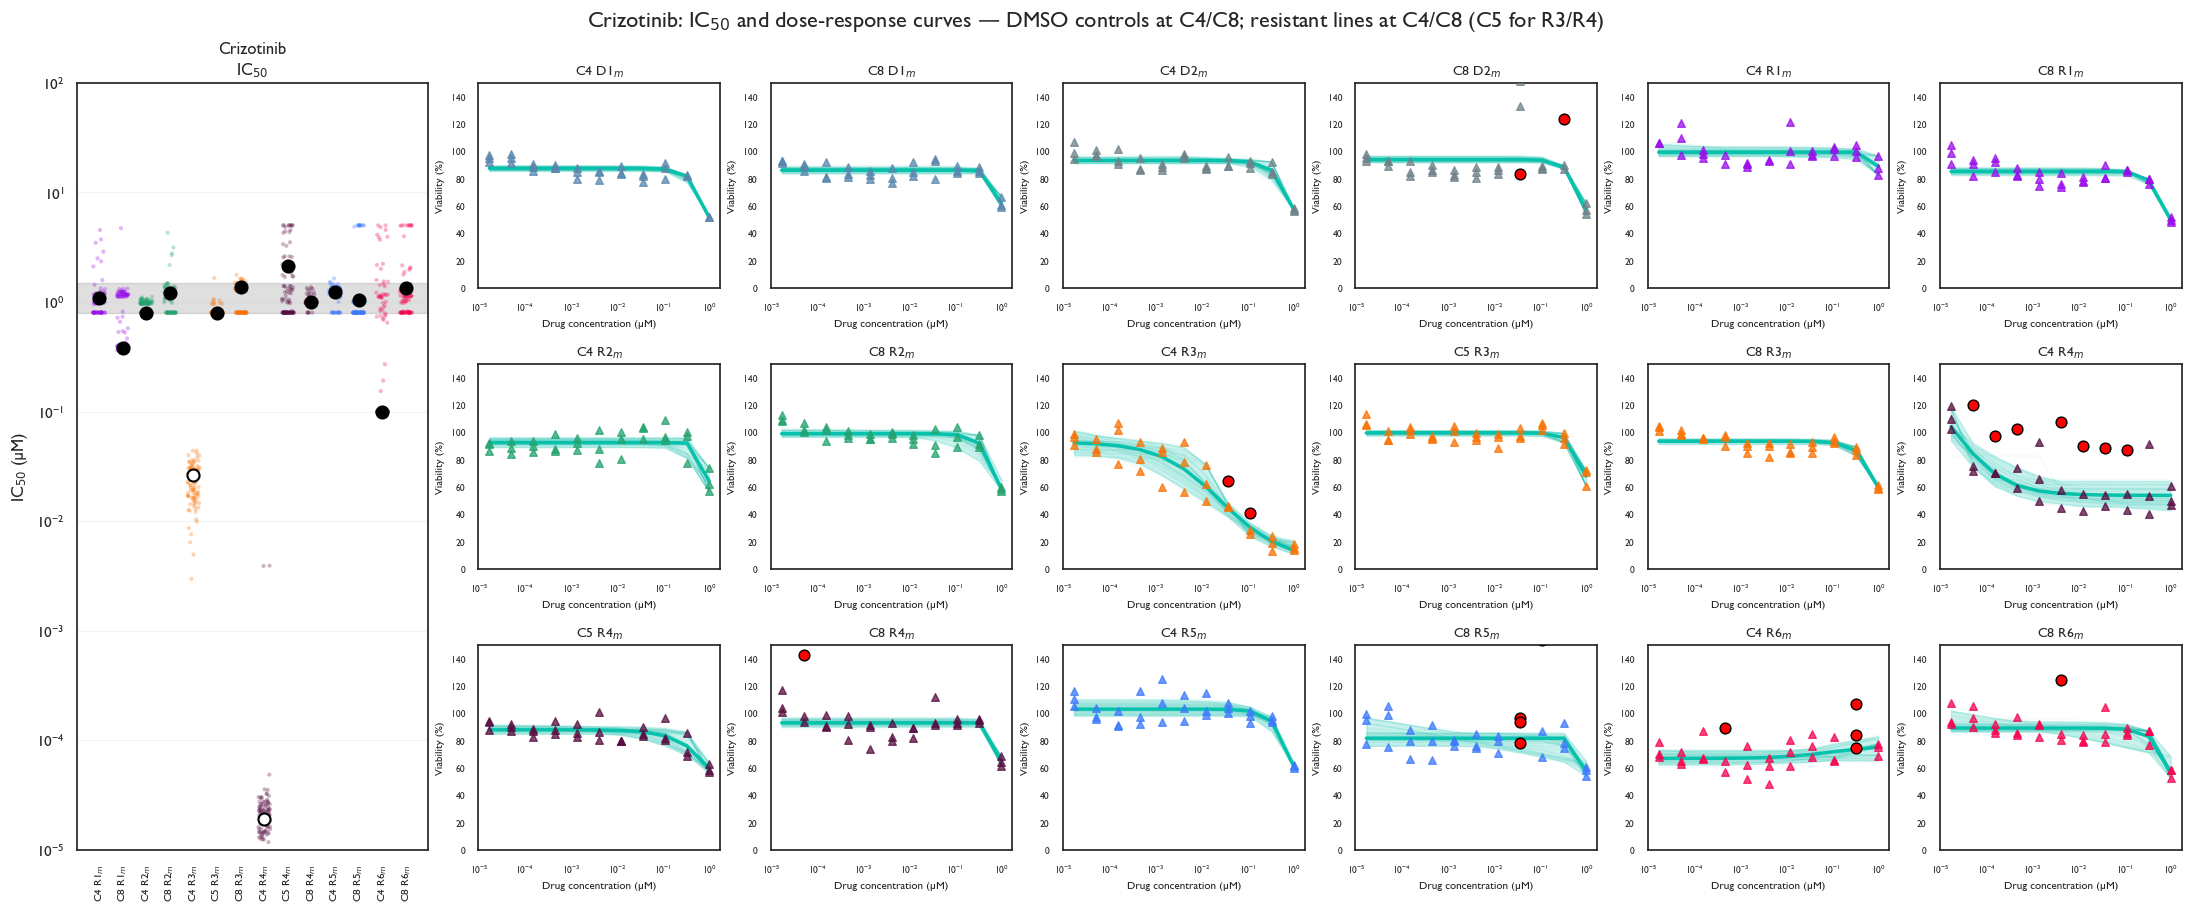

crizotinib: 18 DRC panels plotted (including 4 D1/D2 control panels).
Saved: CS_drc_crizotinib_C4_C5_C8_with_controls_ic50_drcs_3.pdf


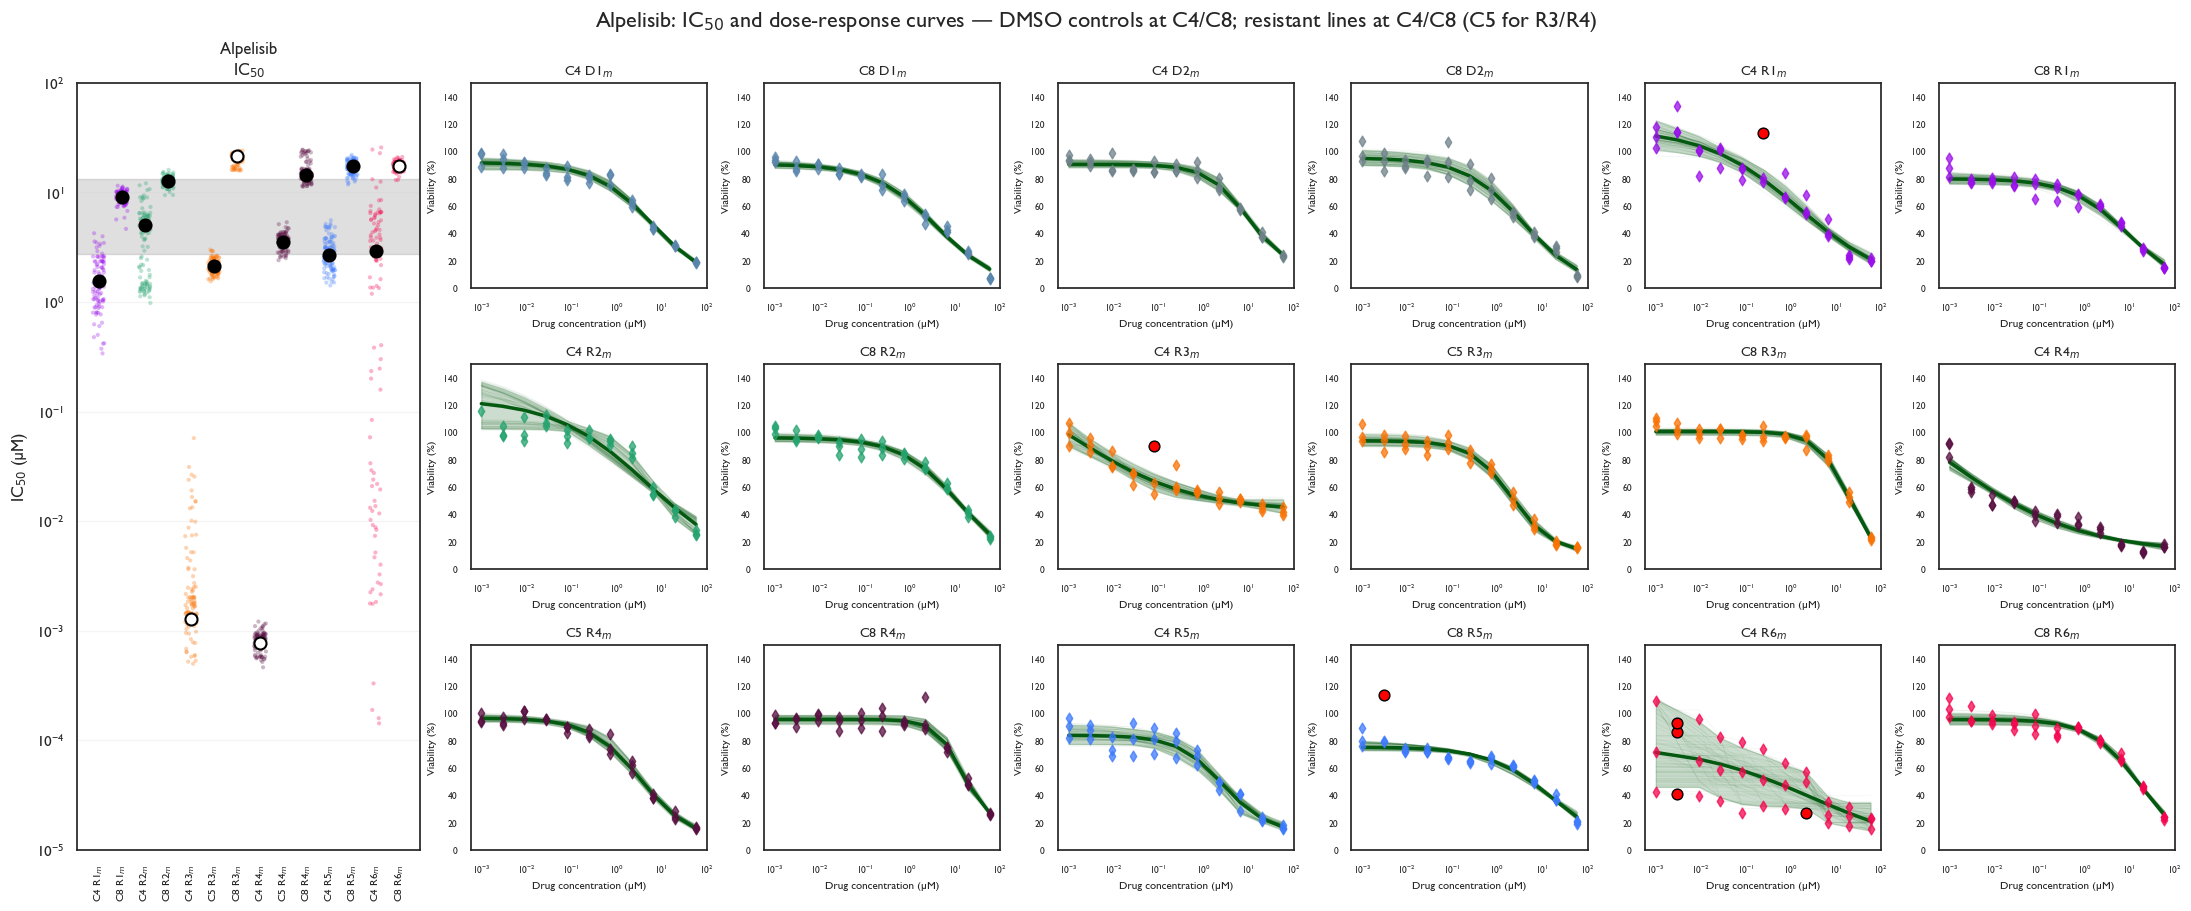

alpelisib: 18 DRC panels plotted (including 4 D1/D2 control panels).
Saved: CS_drc_alpelisib_C4_C5_C8_with_controls_ic50_drcs_3.pdf


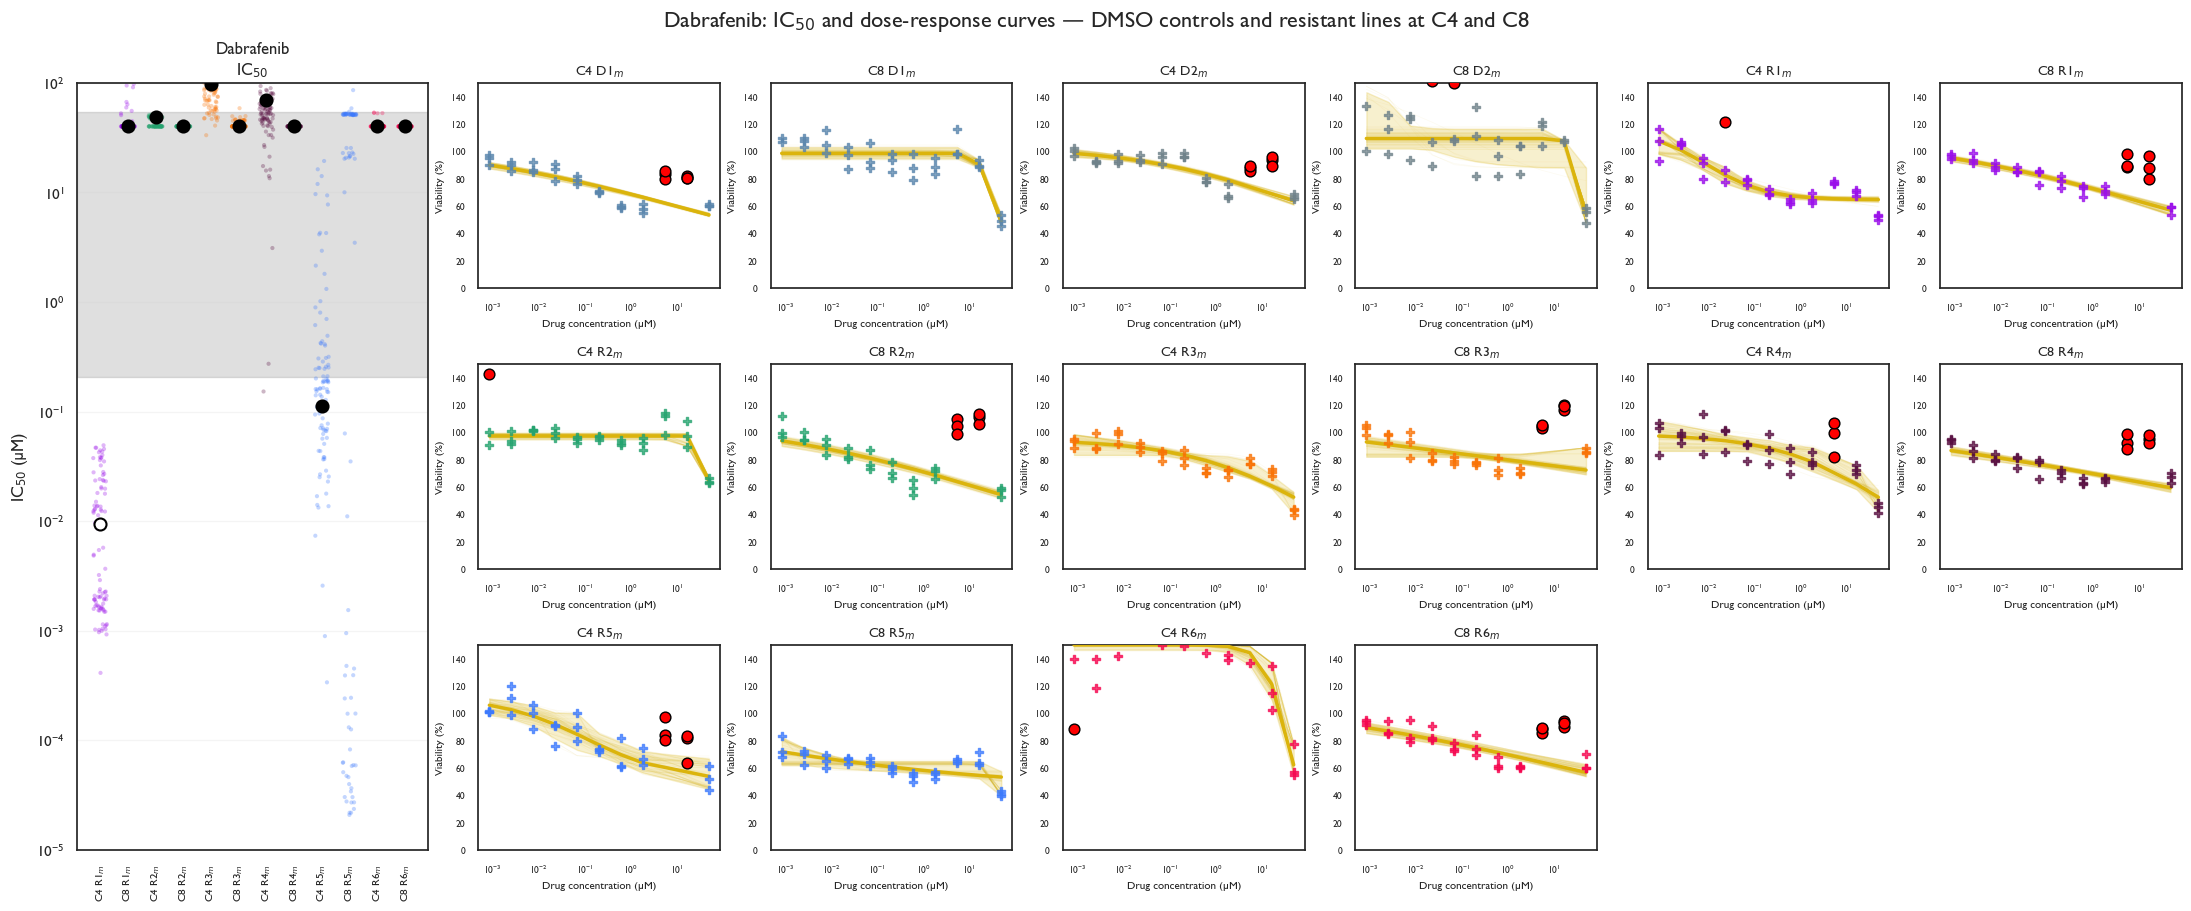

dabrafenib: 16 DRC panels plotted (including 4 D1/D2 control panels).
Saved: CS_drc_dabrafenib_C4_C8_with_controls_ic50_drcs_3.pdf


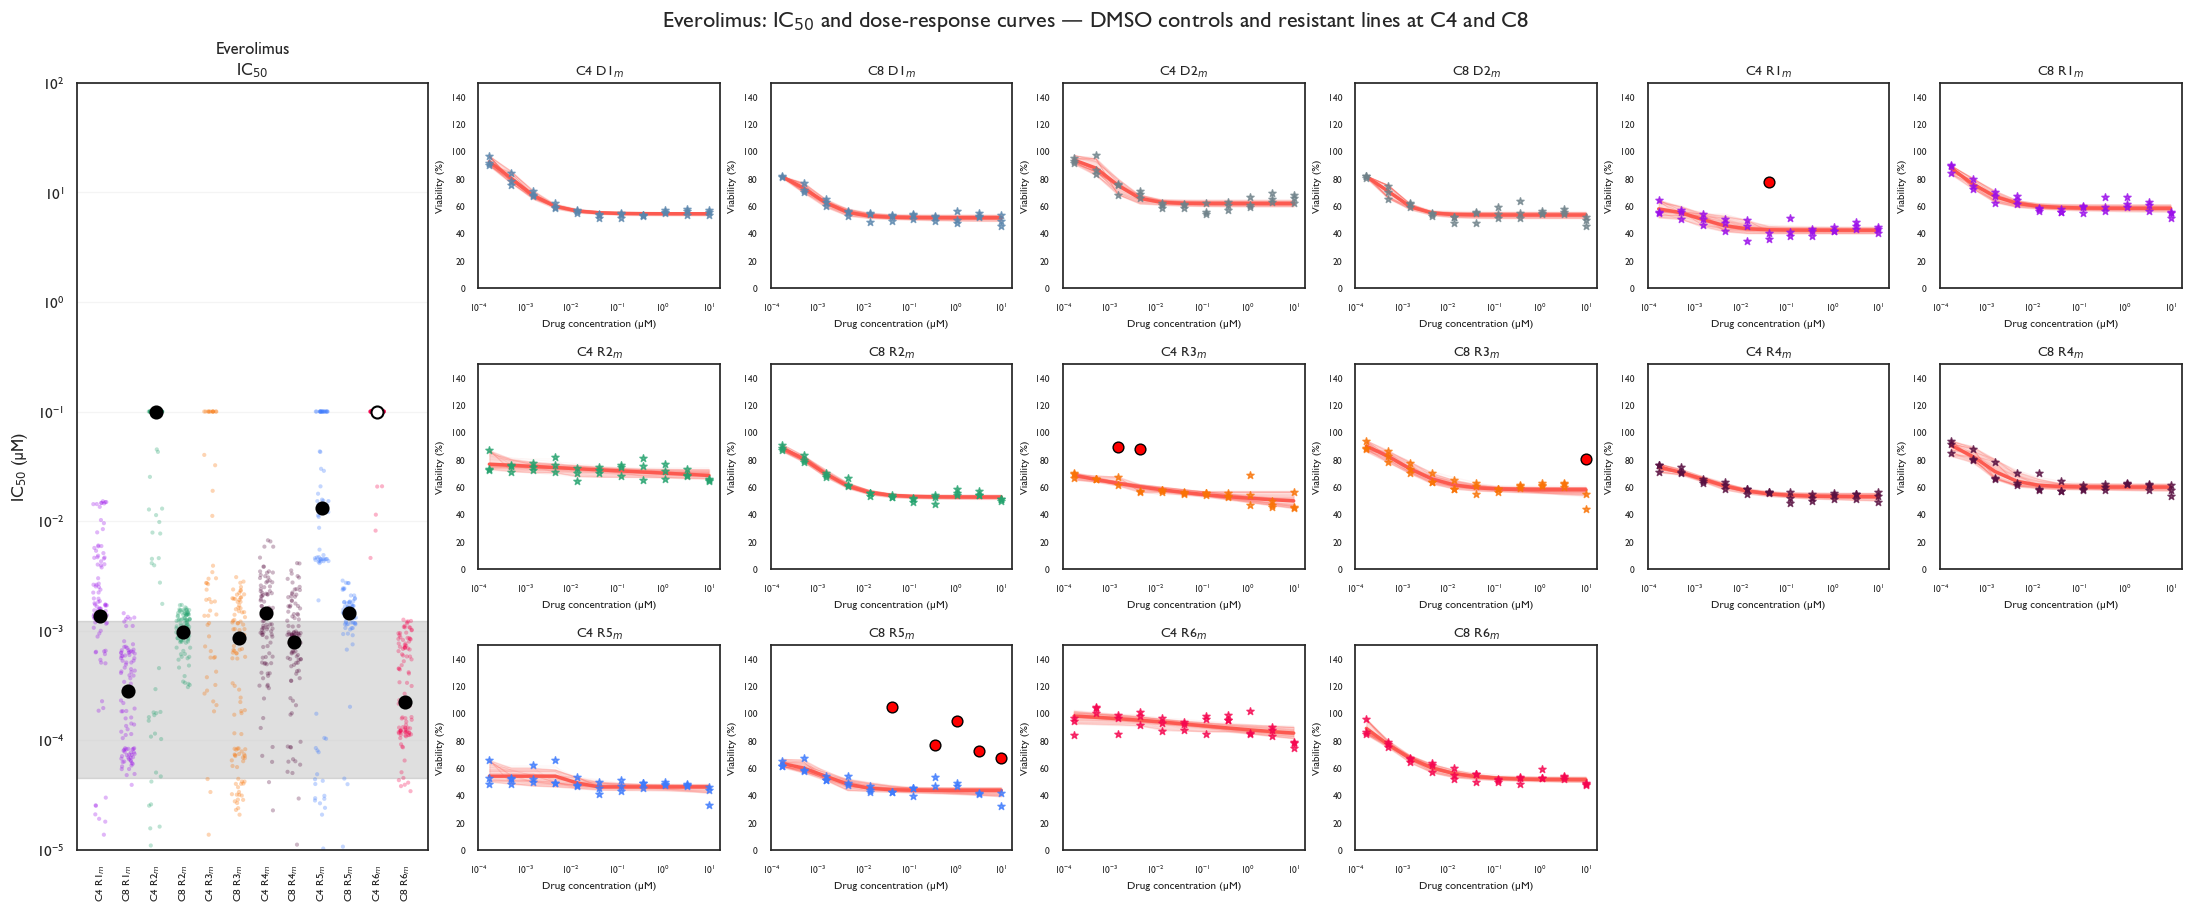

everolimus: 16 DRC panels plotted (including 4 D1/D2 control panels).
Saved: CS_drc_everolimus_C4_C8_with_controls_ic50_drcs_3.pdf


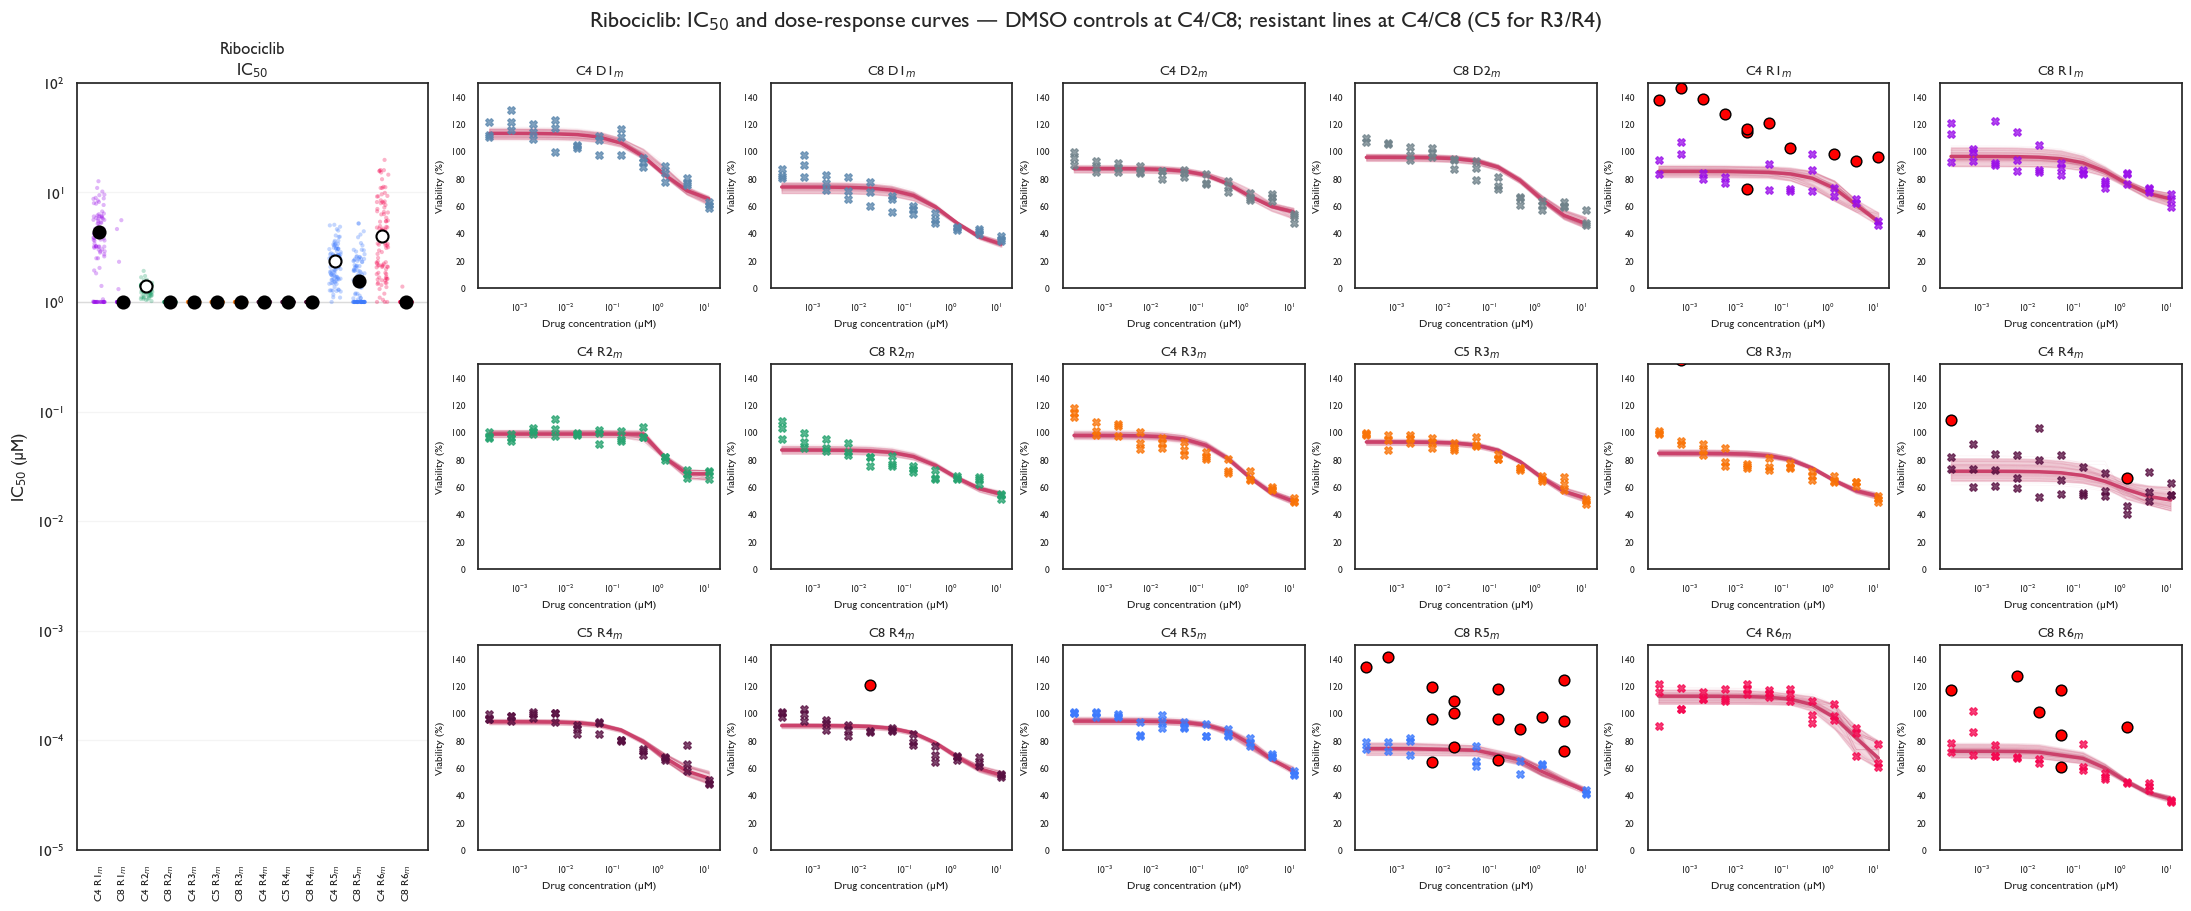

ribociclib: 18 DRC panels plotted (including 4 D1/D2 control panels).
Saved: CS_drc_ribociclib_C4_C5_C8_with_controls_ic50_drcs_3.pdf


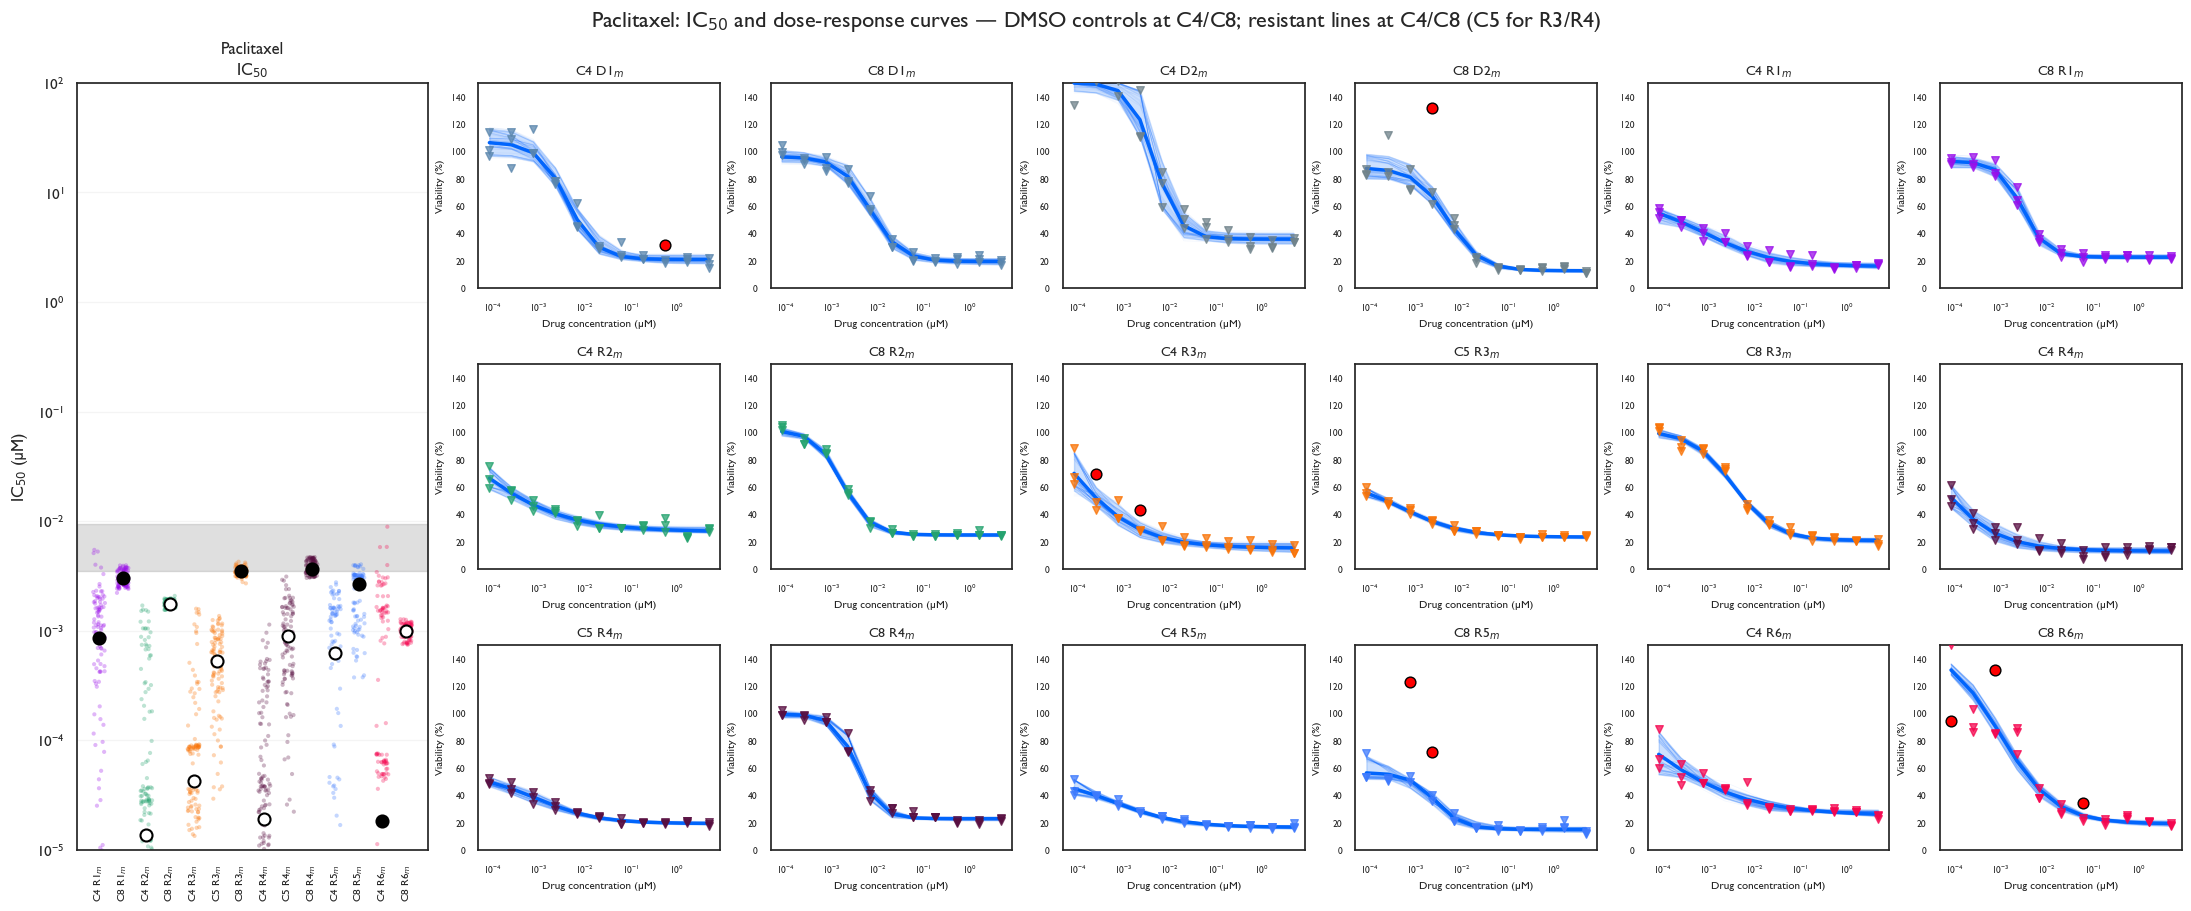

paclitaxel: 18 DRC panels plotted (including 4 D1/D2 control panels).
Saved: CS_drc_paclitaxel_C4_C5_C8_with_controls_ic50_drcs_3.pdf


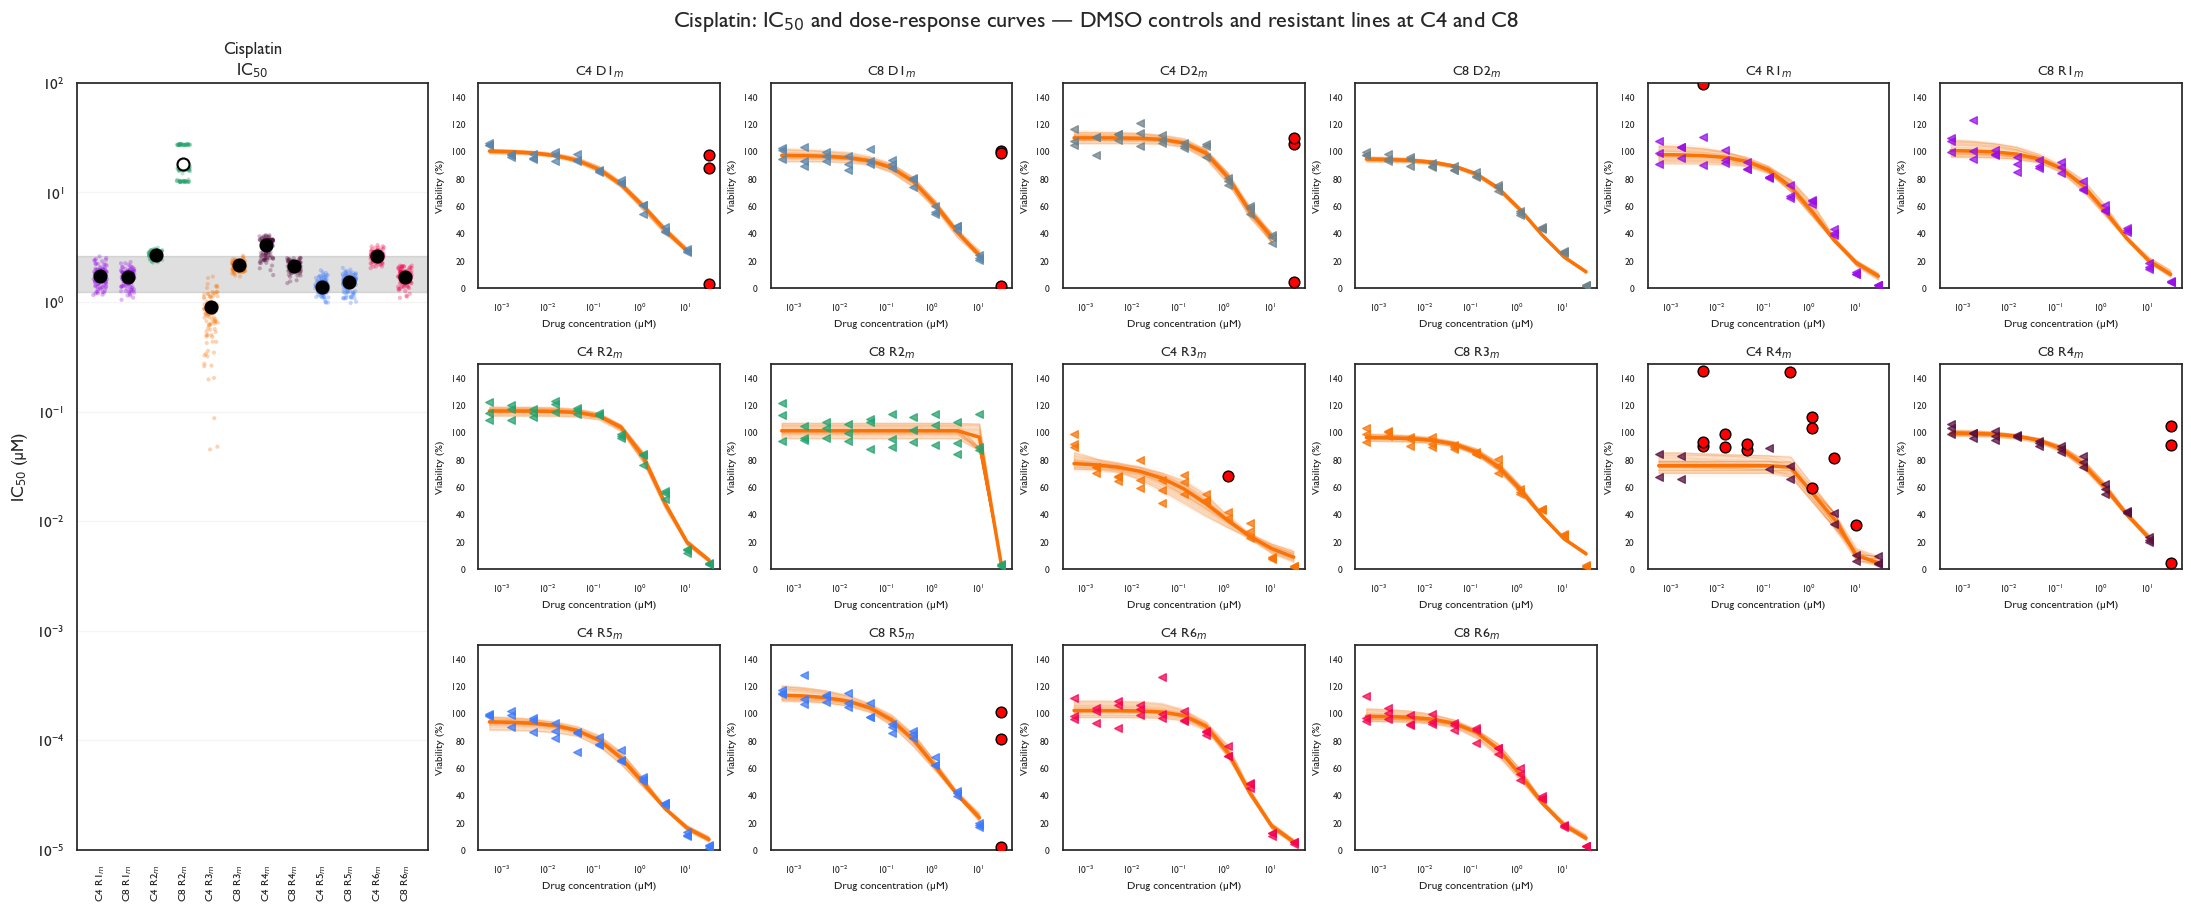

cisplatin: 16 DRC panels plotted (including 4 D1/D2 control panels).
Saved: CS_drc_cisplatin_C4_C8_with_controls_ic50_drcs_3.pdf


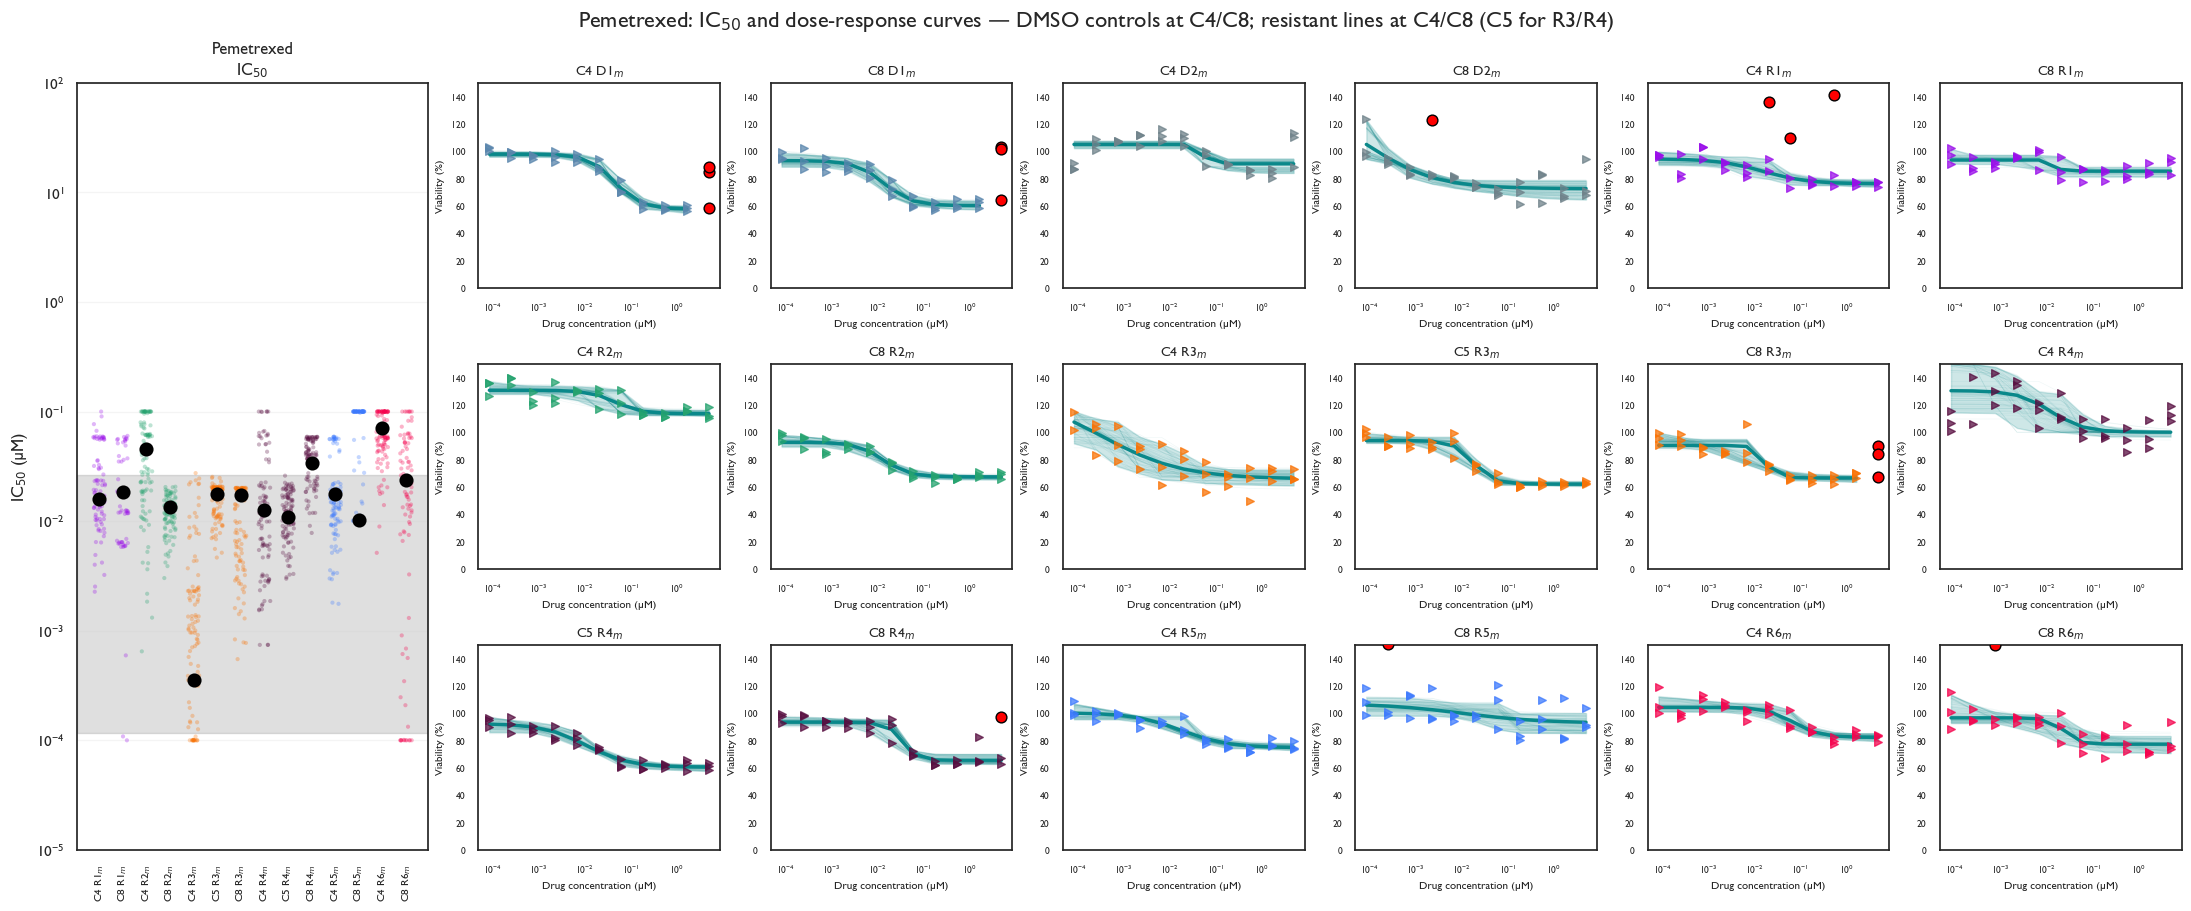

pemetrexed: 18 DRC panels plotted (including 4 D1/D2 control panels).
Saved: CS_drc_pemetrexed_C4_C5_C8_with_controls_ic50_drcs_3.pdf


In [8]:
params_df = pd.read_csv(os.path.join(data_dir, "CS_drc_params_c0458_3.csv"), index_col=0)
fit_df = pd.read_csv(os.path.join(data_dir, "CS_drc_fit_c0458_3.csv"), index_col=0)
params_df_bootstraps = pd.read_csv(os.path.join(data_dir,"CS_drc_params_bootstrap_c0458_3.csv"), index_col=0)
fit_df_bootstraps = pd.read_csv(os.path.join(data_dir, "CS_drc_fit_bootstrap_c0458_3.csv"), index_col=0)


results_df_all = pd.read_csv(os.path.join(data_dir, "CS_cleaned_c0458_2.csv"), index_col=0)
# ------------------------------------------------------------
# Make sure previous significance section was run
# ------------------------------------------------------------
if "StatDifferent" not in params_df.columns:

    raise ValueError(
        "StatDifferent is missing from "
        "CS_drc_params_c0458_3.csv. "
        "Run the previous significance-analysis section first."
    )

# ============================================================
# 2. Analysis settings
# ============================================================
resistant_replicates = ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"]
# ------------------------------------------------------------
# Cycles that may appear for resistant replicates
# ------------------------------------------------------------
cycles_to_plot = [4, 5, 8]
# ------------------------------------------------------------
# C8 controls used in pooled IC50 reference
#
# Parental C0 is handled separately because C0 was duplicated across replicate labels during preprocessing.
# ------------------------------------------------------------
c8_control_replicates = ["D1-m", "D2-m"]

# ------------------------------------------------------------
# NEW: D1/D2 control DRCs to display on right-hand side
# ------------------------------------------------------------
control_drc_order = ["D1-m C4", "D1-m C8", "D2-m C4", "D2-m C8"]

# ------------------------------------------------------------
# Drugs with C5 data for R3/R4
# ------------------------------------------------------------
c5_drugs = ["lapatinib", "crizotinib", "alpelisib", "ribociclib", "paclitaxel", "pemetrexed"]

# ------------------------------------------------------------
# All collateral drugs
# ------------------------------------------------------------
drugs = ["osimertinib", "lapatinib", "crizotinib", "alpelisib", "dabrafenib", "everolimus", "ribociclib", "paclitaxel", "cisplatin", "pemetrexed"]

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------
figure_dir = os.path.join(data_dir, "figures")
os.makedirs(figure_dir, exist_ok=True)

# ============================================================
# 3. Original resistant plotting order
# ============================================================
def get_plotting_order(drug_name):
    plotting_order = []
    for replicate_name in resistant_replicates:
        plotting_order.append(f"{replicate_name} C4")

        if (drug_name in c5_drugs and replicate_name in ["R3-m", "R4-m"]):
            plotting_order.append(f"{replicate_name} C5")

        plotting_order.append(f"{replicate_name} C8")
    return plotting_order


# ============================================================
# 4. NEW: Right-side DRC plotting order
# ============================================================
def get_drc_plotting_order(drug_name):
    drc_plotting_order = (control_drc_order.copy())
    drc_plotting_order.extend(get_plotting_order(drug_name))
    return drc_plotting_order


# ============================================================
# 5. Function: IC50 summary panel
# ============================================================
def plot_ic50(ax, drug_name, plotting_order):

    # --------------------------------------------------------
    # Bootstrap IC50 estimates
    # R1-R6
    # C4 / C5 / C8
    # --------------------------------------------------------
    ic50_df = params_df_bootstraps[(params_df_bootstraps["Drug"] == drug_name) &
        (params_df_bootstraps["Parameter"] == "ic50") &
        (params_df_bootstraps["ReplicateName"].isin(resistant_replicates)) &
        (params_df_bootstraps["CycleId"].isin(cycles_to_plot))].copy()

    ic50_df["Group"] = (ic50_df["ReplicateName"] + " C" + ic50_df["CycleId"].astype(int).astype(str))

    # --------------------------------------------------------
    # Keep only groups requested for this drug
    # --------------------------------------------------------
    ic50_df = ic50_df[ic50_df["Group"].isin(plotting_order)].copy()
    # --------------------------------------------------------
    # Main fitted IC50 estimates
    # --------------------------------------------------------
    main_ic50_df = params_df[(params_df["Drug"] == drug_name) &
        (params_df["Parameter"] == "ic50") &
        (params_df["ReplicateName"].isin(resistant_replicates)) &
        (params_df["CycleId"].isin(cycles_to_plot))].copy()

    main_ic50_df["Group"] = (main_ic50_df["ReplicateName"] + " C" + main_ic50_df["CycleId"].astype(int).astype(str))
    main_ic50_df = main_ic50_df[main_ic50_df["Group"].isin(plotting_order)].copy()

    # ========================================================
    # Correct pooled control bootstrap IC50
    # ========================================================
    control_values = params_df_bootstraps.loc[((((params_df_bootstraps["ReplicateName"] == "D1-m") &
                    (params_df_bootstraps["CycleId"] == 0)) | ((params_df_bootstraps["ReplicateName"].isin(c8_control_replicates)) &
                    (params_df_bootstraps["CycleId"] == 8))) &
            (params_df_bootstraps["Drug"] == drug_name) &
            (params_df_bootstraps["Parameter"] == "ic50")), "Value"].dropna()

    # --------------------------------------------------------
    # Grey pooled-control 95% CI
    # --------------------------------------------------------
    if not control_values.empty:
        control_lower = (control_values.quantile((1 - significance_level_ci) / 2))
        control_upper = (control_values.quantile((1 + significance_level_ci) / 2))
        ax.axhspan(control_lower, control_upper, color="grey", alpha=0.25, zorder=0)

    # --------------------------------------------------------
    # Bootstrap IC50 distributions
    # --------------------------------------------------------
    sns.stripplot(
        x="Group",
        y="Value",
        hue="ReplicateName",
        order=plotting_order,
        data=ic50_df,
        jitter=0.25,
        dodge=False,
        size=3,
        alpha=0.30,
        palette=replicate_palette,
        legend=False,
        ax=ax,
        zorder=1
    )


    # --------------------------------------------------------
    # Main MLE IC50 estimates
    #
    # White = CI does NOT overlap pooled-control CI
    # Black = CI overlaps pooled-control CI
    # --------------------------------------------------------
    group_positions = {group: i for i, group in enumerate(plotting_order)}
    for _, row in main_ic50_df.iterrows():
        group = row["Group"]
        if group not in group_positions:
            continue

        x_pos = (group_positions[group])
        stat_different = (row["StatDifferent"])

        # ----------------------------------------------------
        # Protect against string booleans
        # ----------------------------------------------------
        if isinstance(stat_different, str):
            stat_different = (stat_different.lower() == "true")

        facecolor = ("white" if stat_different else "black")

        ax.scatter(
            x_pos,
            row["MLE"],
            s=75,
            facecolor=facecolor,
            edgecolor="black",
            linewidth=1.5,
            zorder=5
        )

    # --------------------------------------------------------
    # IC50 panel formatting
    # --------------------------------------------------------
    ax.set_title(f"{drug_name.capitalize()}\n"
        f"IC$_{{50}}$",
        fontsize=12
    )


    ax.set_yscale("log")
    ax.set_ylim(1e-5, 1e2)
    ax.set_ylabel("IC$_{50}$ (µM)")
    ax.set_xlabel("")
    ax.set_xticks(range(len(plotting_order)))

    # --------------------------------------------------------
    # Format resistant labels
    # R3-m C5 -> C5 R3_m
    # --------------------------------------------------------
    formatted_labels = []

    for group in plotting_order:
        replicate_name, cycle_label = (group.split(" "))
        replicate_number = (replicate_name.replace("R", "").replace("-m", ""))
        formatted_labels.append(
            rf"{cycle_label} "
            rf"R{replicate_number}$_m$"
        )


    ax.set_xticklabels(formatted_labels, rotation=90, fontsize=8)
    # --------------------------------------------------------
    # Major grid only
    # --------------------------------------------------------
    ax.grid(True, axis="y", which="major", alpha=0.20)
    ax.grid(False, axis="y", which="minor")

# ============================================================
# 6. Function: individual dose-response curve
# ============================================================
def plot_drc(ax, replicate, cycle_id, drug_name):
    # --------------------------------------------------------
    # Experimental observations
    # --------------------------------------------------------
    curr_df = results_df_all[(results_df_all["ReplicateName"] == replicate) &
        (results_df_all["CycleId"] == cycle_id) &
        (results_df_all["Drug"] == drug_name) &
        (results_df_all["DrugConcentration"] > 0)].copy()

    # --------------------------------------------------------
    # Handle IsOutlier safely
    # --------------------------------------------------------
    if "IsOutlier" in curr_df.columns:
        if (curr_df["IsOutlier"].dtype == bool):
            outlier_mask = (curr_df["IsOutlier"].fillna(False))
        else:
            outlier_mask = (curr_df["IsOutlier"].fillna(False).astype(str).str.lower().eq("true"))


    else:
        outlier_mask = pd.Series(False, index=curr_df.index)

    # --------------------------------------------------------
    # Clean observations
    #
    # Only these observations contributed to the fit.
    # --------------------------------------------------------
    clean_df = curr_df[(~outlier_mask) &
        (curr_df["Viability_cleaned"].notna())]

    # --------------------------------------------------------
    # Clean experimental points
    # --------------------------------------------------------
    ax.scatter(clean_df["DrugConcentration"],
        clean_df["Viability_cleaned"],
        color=replicate_palette[replicate],
        marker=marker_palette[drug_name],
        s=30,
        alpha=0.75,
        zorder=5
    )

    # --------------------------------------------------------
    # Excluded outliers
    #
    # Displayed for QC only.
    # NOT used for fitting.
    # --------------------------------------------------------
    outliers = curr_df[outlier_mask]
    if not outliers.empty:
        ax.scatter(outliers["DrugConcentration"],
            outliers["Viability"],
            color="red",
            s=60,
            edgecolor="black",
            linewidth=1,
            zorder=6
        )

    # --------------------------------------------------------
    # Bootstrap fitted curves
    # --------------------------------------------------------
    prediction_df_bootstrap = (fit_df_bootstraps[(fit_df_bootstraps["ReplicateName"] == replicate) &
            (fit_df_bootstraps["CycleId"] == cycle_id) &
            (fit_df_bootstraps["Drug"] == drug_name)].copy())

    if (not prediction_df_bootstrap.empty and "BootstrapId" in prediction_df_bootstrap.columns):
        prediction_df_bootstrap = (prediction_df_bootstrap.sort_values(["BootstrapId", "DrugConcentration"]))

        sns.lineplot(
            x="DrugConcentration",
            y="Viability_cleaned",
            units="BootstrapId",
            estimator=None,
            color=drug_palette[drug_name],
            linewidth=0.5,
            alpha=0.06,
            legend=False,
            data=prediction_df_bootstrap,
            ax=ax,
            zorder=1
        )

    # --------------------------------------------------------
    # Main fitted DRC
    # --------------------------------------------------------
    prediction_df = fit_df[(fit_df["ReplicateName"] == replicate) &
        (fit_df["CycleId"] == cycle_id) &
        (fit_df["Drug"] == drug_name)].copy()

    if not prediction_df.empty:
        prediction_df = (prediction_df.sort_values("DrugConcentration"))

        # ----------------------------------------------------
        # Individual fitted-curve 95% CI
        # Same for D1/D2 and resistant replicates.
        # ----------------------------------------------------
        ax.fill_between(prediction_df["DrugConcentration"].to_numpy(dtype=float),
            prediction_df["LowerCI"].to_numpy(dtype=float),
            prediction_df["UpperCI"].to_numpy(dtype=float),
            color=drug_palette[drug_name],
            alpha=0.20,
            zorder=2
        )

        # ----------------------------------------------------
        # Main fitted curve
        # ----------------------------------------------------
        ax.plot(prediction_df["DrugConcentration"],
            prediction_df["Viability_cleaned"],
            color=drug_palette[drug_name],
            linewidth=2.5,
            zorder=3
        )

    # --------------------------------------------------------
    # Axis formatting
    # --------------------------------------------------------
    ax.set_xscale("log")
    ax.set_ylim(0, 150)

    # ========================================================
    # NEW:
    # Format title correctly for either D or R replicate
    # Examples:
    # D1-m -> C4 D1_m
    # R3-m -> C8 R3_m
    # ========================================================
    replicate_prefix = (replicate[0])
    replicate_number = (replicate.replace(replicate_prefix, "", 1).replace("-m", ""))
    ax.set_title(
        rf"C{cycle_id} "
        rf"{replicate_prefix}"
        rf"{replicate_number}$_m$",
        fontsize=10
    )

    ax.set_xlabel("Drug concentration (µM)", fontsize=8)
    ax.set_ylabel("Viability (%)", fontsize=8)
    ax.tick_params(labelsize=7)
# ============================================================
# 7. Generate one complete figure for each drug
# LEFT: Original resistant IC50 summary
#
# RIGHT:
#   D1 C4
#   D1 C8
#   D2 C4
#   D2 C8
#   +
#   original resistant C4/C5/C8 DRCs
# ============================================================
for drug_name in drugs:
    # --------------------------------------------------------
    # Original resistant-only order for LEFT IC50 panel
    # --------------------------------------------------------
    plotting_order = (get_plotting_order(drug_name))
    # --------------------------------------------------------
    # Expanded order for RIGHT-SIDE DRCs
    # --------------------------------------------------------
    drc_plotting_order = (get_drc_plotting_order(drug_name))
    n_panels = len(drc_plotting_order)

    # --------------------------------------------------------
    # Keep original 3-row layout
    # --------------------------------------------------------
    n_rows = 3
    n_right_cols = math.ceil(n_panels / n_rows)

    # --------------------------------------------------------
    # Dynamic figure width
    # --------------------------------------------------------
    fig_width = (5.0 + 2.8 * n_right_cols)
    fig = plt.figure(figsize=(fig_width, 9), layout="constrained")

    # --------------------------------------------------------
    # Grid:
    # first column = IC50 summary
    # remaining columns = DRC panels
    # --------------------------------------------------------
    gs = fig.add_gridspec(nrows=n_rows, ncols=(n_right_cols + 1), width_ratios=([1.45] + [1] * n_right_cols))

    # ========================================================
    # LEFT IC50 panel
    # Original resistant-only IC50 analysis
    # ========================================================
    ax_left = fig.add_subplot(gs[:, 0])
    plot_ic50(ax_left, drug_name, plotting_order)
    # --------------------------------------------------------
    # Create right-side axes
    # --------------------------------------------------------
    right_axes = []

    for i in range(n_rows * n_right_cols):
        row_id = (i // n_right_cols)
        col_id = (i % n_right_cols)
        ax = fig.add_subplot(gs[row_id, col_id + 1])
        right_axes.append(ax)
    # ========================================================
    # Plot expanded DRC set
    # Includes:D1/D2 C4+C8 + original resistant C4/C5/C8
    # ========================================================
    for i, group in enumerate(drc_plotting_order):
        replicate_name, cycle_label = (group.split(" "))
        cycle_id = int(cycle_label.replace("C", ""))
        plot_drc(right_axes[i], replicate_name, cycle_id, drug_name)

    # --------------------------------------------------------
    # Hide unused axes
    # --------------------------------------------------------
    for i in range(n_panels, len(right_axes)):
        right_axes[i].set_visible(False)

    # ========================================================
    # Overall title
    # ========================================================
    if drug_name in c5_drugs:
        cycle_title = (
            "DMSO controls at C4/C8; "
            "resistant lines at C4/C8 "
            "(C5 for R3/R4)"
        )

    else:
        cycle_title = (
            "DMSO controls and resistant lines "
            "at C4 and C8"
        )

    fig.suptitle(
        f"{drug_name.capitalize()}: "
        f"IC$_{{50}}$ and dose-response curves — "
        f"{cycle_title}",
        fontsize=16
    )

    # ========================================================
    # Save revised figure
    # New filename so original resistant-only version remains.
    # ========================================================
    output_file = os.path.join(figure_dir,
        (f"CS_drc_{drug_name}_" f"C4_C5_C8_with_controls_ic50_drcs_3.pdf"
            if drug_name in c5_drugs
            else
            f"CS_drc_{drug_name}_" f"C4_C8_with_controls_ic50_drcs_3.pdf"))

    plt.savefig(output_file, bbox_inches="tight")
    plt.show()

    print(
        f"{drug_name}: "
        f"{n_panels} DRC panels plotted "
        f"(including 4 D1/D2 control panels)."
    )


    print(
        f"Saved: "
        f"{os.path.basename(output_file)}"
    )

Comparisons with non-overlapping 95% bootstrap IC50 intervals:


,Drug,Group,Control_IC50,C8_IC50,Control_CI_low,Control_CI_high,C8_CI_low,C8_CI_high
20,alpelisib,C8 R3-m,3.87099,21.49428,2.75807,13.21721,15.96518,23.71951
23,alpelisib,C8 R6-m,3.87099,17.27990,2.75807,13.21721,14.27785,20.38672
49,cisplatin,C8 R2-m,2.14235,18.23861,1.23669,2.60879,12.44387,27.55415
6,lapatinib,C8 R1-m,0.61950,7.36029,0.06202,3.57222,5.18446,11.44644
8,lapatinib,C8 R3-m,0.61950,9.86256,0.06202,3.57222,8.80517,10.97431
10,lapatinib,C8 R5-m,0.61950,5.88947,0.06202,3.57222,3.69674,8.92911
11,lapatinib,C8 R6-m,0.61950,6.49098,0.06202,3.57222,4.85852,7.92655
0,osimertinib,C8 R1-m,0.62982,1.94928,0.33130,1.22733,1.39031,2.56118
1,osimertinib,C8 R2-m,0.62982,2.03730,0.33130,1.22733,1.74514,2.35555
2,osimertinib,C8 R3-m,0.62982,3.24168,0.33130,1.22733,2.55516,4.03355



14 of 60 comparisons have non-overlapping 95% bootstrap CIs.


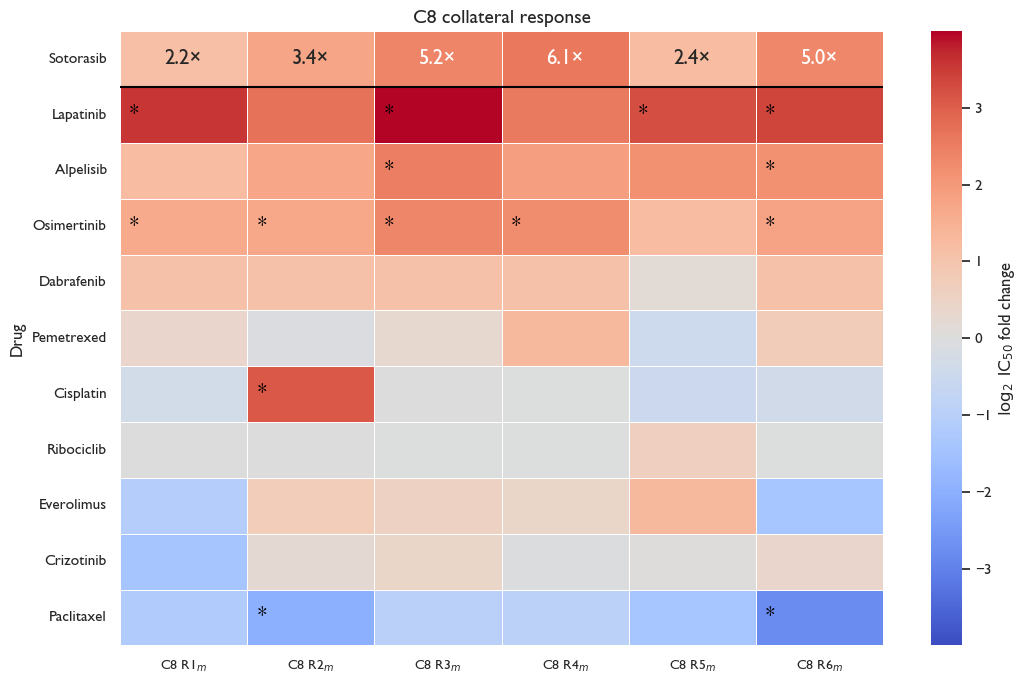

       Drug   Group  Control_IC50   C8_IC50  FoldChange  Log2IC50FoldChange  Control_CI_low  Control_CI_high  C8_CI_low  C8_CI_high StatDifferent
osimertinib C8 R1-m      0.629820  1.949284    3.094984            1.629932        0.331298         1.227331   1.390305    2.561178          True
osimertinib C8 R2-m      0.629820  2.037303    3.234736            1.693648        0.331298         1.227331   1.745143    2.355554          True
osimertinib C8 R3-m      0.629820  3.241682    5.146994            2.363730        0.331298         1.227331   2.555158    4.033547          True
osimertinib C8 R4-m      0.629820  2.935235    4.660432            2.220464        0.331298         1.227331   2.057775    3.682117          True
osimertinib C8 R5-m      0.629820  1.475645    2.342962            1.228334        0.331298         1.227331   0.804300    2.136232         False
osimertinib C8 R6-m      0.629820  2.180612    3.462276            1.791721        0.331298         1.227331   1.415756    3

In [9]:
# ------------------------------------------------------------
# 1. Definitions
# ------------------------------------------------------------

resistant_replicates = [
    "R1-m",
    "R2-m",
    "R3-m",
    "R4-m",
    "R5-m",
    "R6-m"
]

collateral_drugs = [
    "osimertinib",
    "lapatinib",
    "crizotinib",
    "alpelisib",
    "dabrafenib",
    "everolimus",
    "ribociclib",
    "paclitaxel",
    "cisplatin",
    "pemetrexed"
]

group_order = [
    "C8 R1-m",
    "C8 R2-m",
    "C8 R3-m",
    "C8 R4-m",
    "C8 R5-m",
    "C8 R6-m"
]


# ------------------------------------------------------------
# Manual IC50 override
#
# Only the point estimate is replaced.
# No bootstrap CI/star is assigned for this condition.
# ------------------------------------------------------------
manual_ic50_overrides = {
    ("dabrafenib", 8, "R5-m"): 21.380561
}


# ============================================================
# 2. Sotorasib row
#
# Relative to parental C0 only.
# No star is assigned to sotorasib here.
# ============================================================
sotorasib_c0 = 0.008338853

sotorasib_ic50_dict = {
    "C8 R1-m": 0.018224939,
    "C8 R2-m": 0.028201779,
    "C8 R3-m": 0.043421243,
    "C8 R4-m": 0.050914542,
    "C8 R5-m": 0.019747379,
    "C8 R6-m": 0.042021419
}

sotorasib_rows = []


for group_name, ic50_value in sotorasib_ic50_dict.items():
    fold_change = (ic50_value / sotorasib_c0)
    log2_fold_change = np.log2(fold_change)
    sotorasib_rows.append(
        {
            "Drug": "sotorasib",
            "Group": group_name,

            "Control_IC50": sotorasib_c0,
            "C8_IC50": ic50_value,

            "FoldChange": fold_change,
            "Log2IC50FoldChange": log2_fold_change,

            "Control_CI_low": np.nan,
            "Control_CI_high": np.nan,

            "C8_CI_low": np.nan,
            "C8_CI_high": np.nan,

            "StatDifferent": np.nan
        }
    )


sotorasib_df = pd.DataFrame(sotorasib_rows)


# ============================================================
# 3. Collateral-drug IC50 fold changes
# ============================================================
summary_list = []
for drug_name in collateral_drugs:

    # ========================================================
    # 3A. Pooled-control fitted IC50 point estimates
    # ========================================================
    control_point_values = params_df.loc[(((params_df["ReplicateName"] == "D1-m") & (params_df["CycleId"] == 0)) | (params_df["ReplicateName"].isin(["D1-m", "D2-m"])
                & (params_df["CycleId"] == 8)))
        & (params_df["Drug"] == drug_name)
        & (params_df["Parameter"] == "ic50"), "MLE"].dropna()


    control_point_values = (control_point_values[control_point_values > 0])


    if control_point_values.empty:

        print(
            f"No pooled-control fitted IC50 "
            f"found for {drug_name}"
        )

        continue


    # --------------------------------------------------------
    # Median pooled-control fitted IC50
    # --------------------------------------------------------
    control_ic50 = (control_point_values.median())

    # ========================================================
    # 3B. Existing pooled-control bootstrap IC50 distribution
    # ========================================================
    control_bootstrap_values = params_df_bootstraps.loc[(((params_df_bootstraps["ReplicateName"] == "D1-m")
                & (params_df_bootstraps["CycleId"] == 0)) | (params_df_bootstraps["ReplicateName"].isin(["D1-m", "D2-m"])
                & (params_df_bootstraps["CycleId"] == 8)))
        & (params_df_bootstraps["Drug"] == drug_name)
        & (params_df_bootstraps["Parameter"] == "ic50"), "Value"].dropna()

    control_bootstrap_values = (control_bootstrap_values[control_bootstrap_values > 0])


    if control_bootstrap_values.empty:
        print(
            f"No pooled-control bootstrap IC50 "
            f"values found for {drug_name}"
        )

        continue


    # --------------------------------------------------------
    # 95% bootstrap CI for pooled control
    # --------------------------------------------------------
    control_ci_low = np.percentile(control_bootstrap_values, 2.5)
    control_ci_high = np.percentile(control_bootstrap_values, 97.5)

    # ========================================================
    # 3C. C8 resistant populations
    # ========================================================
    for replicate_name in resistant_replicates:
        condition_key = (drug_name, 8, replicate_name)

        # ====================================================
        # Manual IC50 override
        # ====================================================
        if condition_key in manual_ic50_overrides:
            target_ic50 = (manual_ic50_overrides[condition_key])
            target_ci_low = np.nan
            target_ci_high = np.nan
            stat_different = np.nan


        else:

            # ------------------------------------------------
            # Fitted IC50 point estimate from params_df
            # ------------------------------------------------
            target_point_values = params_df.loc[
                (params_df["Drug"] == drug_name)
                & (params_df["Parameter"] == "ic50")
                & (params_df["CycleId"] == 8)
                & (params_df["ReplicateName"] == replicate_name), "MLE"].dropna()

            target_point_values = (target_point_values[target_point_values > 0])
            if target_point_values.empty:
                print(
                    f"No fitted C8 IC50 found for "
                    f"{drug_name}, {replicate_name}"
                )

                continue

            target_ic50 = (target_point_values.median())

            # ================================================
            # Existing n=100 bootstrap IC50 values
            # ================================================
            target_bootstrap_values = (params_df_bootstraps.loc[(params_df_bootstraps["Drug"] == drug_name)
                    & (params_df_bootstraps["Parameter"] == "ic50")
                    & (params_df_bootstraps["CycleId"] == 8)
                    & (params_df_bootstraps["ReplicateName"] == replicate_name), "Value"].dropna())

            target_bootstrap_values = (target_bootstrap_values[target_bootstrap_values > 0])


            if target_bootstrap_values.empty:
                print(
                    f"No bootstrap C8 IC50 values found for "
                    f"{drug_name}, {replicate_name}"
                )

                continue


            # ------------------------------------------------
            # 95% bootstrap CI for resistant population
            # ------------------------------------------------
            target_ci_low = np.percentile(target_bootstrap_values, 2.5)
            target_ci_high = np.percentile(target_bootstrap_values, 97.5)

            # ------------------------------------------------
            # Star if 95% bootstrap CIs DO NOT overlap
            #
            # This is NOT a p-value.
            # ------------------------------------------------
            stat_different = ((target_ci_high < control_ci_low) or (target_ci_low > control_ci_high))

        # ====================================================
        # IC50 fold change
        # ====================================================
        fold_change = (target_ic50 / control_ic50)
        log2_fold_change = np.log2(fold_change)


        # ====================================================
        # Save result
        # ====================================================
        summary_list.append(
            {
                "Drug": drug_name,
                "Group": (f"C8 {replicate_name}"),
                "Control_IC50": control_ic50,
                "C8_IC50": target_ic50,
                "FoldChange": fold_change,
                "Log2IC50FoldChange": log2_fold_change,
                "Control_CI_low": control_ci_low,
                "Control_CI_high": control_ci_high,
                "C8_CI_low": target_ci_low,
                "C8_CI_high": target_ci_high,
                "StatDifferent": stat_different
            }
        )


# ============================================================
# 4. Create collateral-drug summary dataframe
# ============================================================
collateral_df = pd.DataFrame(summary_list)


if collateral_df.empty:
    raise ValueError("No collateral IC50 comparisons were generated.")

# ============================================================
# 5. Print comparisons with non-overlapping 95% bootstrap CIs
# ============================================================
print(
    "Comparisons with non-overlapping "
    "95% bootstrap IC50 intervals:"
)


starred_df = collateral_df.loc[
    collateral_df["StatDifferent"] == True,
    [
        "Drug",
        "Group",
        "Control_IC50",
        "C8_IC50",
        "Control_CI_low",
        "Control_CI_high",
        "C8_CI_low",
        "C8_CI_high"
    ]
]


display(starred_df.sort_values(["Drug", "Group"]).round(5))


print(
    f"\n{len(starred_df)} of "
    f"{len(collateral_df)} comparisons "
    f"have non-overlapping 95% bootstrap CIs."
)


# ============================================================
# 6. Order collateral drugs
# ============================================================
drug_order = (collateral_df.groupby("Drug")["Log2IC50FoldChange"].mean().sort_values( ascending=False).index.tolist())


# Keep sotorasib fixed at top
final_drug_order = (["sotorasib"] + drug_order)

# ============================================================
# 7. Combine sotorasib + collateral results
# ============================================================
heatmap_df = pd.concat([sotorasib_df, collateral_df], axis=0, ignore_index=True)


# ============================================================
# 8. Heatmap matrix
# ============================================================
fold_change_matrix = (heatmap_df.pivot(index="Drug", columns="Group", values="Log2IC50FoldChange").reindex(index=final_drug_order, columns=group_order))

# ============================================================
# 9. Star matrix
#
# True  = *
# False = no star
# NaN   = no CI comparison available
# ============================================================
significance_matrix = (heatmap_df.pivot(index="Drug", columns="Group", values="StatDifferent").reindex(index=final_drug_order, columns=group_order))

# ============================================================
# 10. Annotation matrix
# ============================================================
annot_matrix = pd.DataFrame(
    "",
    index=fold_change_matrix.index,
    columns=fold_change_matrix.columns
)

for group_name in group_order:

    fold_change = (sotorasib_ic50_dict[group_name] / sotorasib_c0)
    annot_matrix.loc["sotorasib", group_name] = f"{fold_change:.1f}×"

# ============================================================
# 11. Symmetric color scale
#
# Red   = increased IC50 / collateral resistance
# White = little or no change
# Blue  = decreased IC50 / collateral sensitivity
# ============================================================
maximum_absolute_value = np.nanmax(np.abs(fold_change_matrix.to_numpy( dtype=float)))

# ============================================================
# 12. Plot heatmap
# ============================================================
fig, ax = plt.subplots(figsize=(11, 7))

sns.heatmap(
    fold_change_matrix,
    annot=annot_matrix,
    fmt="",
    cmap="coolwarm",
    center=0,
    vmin=-maximum_absolute_value,
    vmax=maximum_absolute_value,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": r"$\log_2$ IC$_{50}$ fold change"},
    annot_kws={"fontsize": 15, "fontweight": "bold"},
    ax=ax
)


# ============================================================
# 13. Add stars
#
# * = non-overlapping 95% bootstrap IC50 intervals
#
# Dabrafenib C8 R5-m receives no star because the manually
# replaced IC50 has no corresponding bootstrap CI.
# ============================================================
for i, drug_name in enumerate(significance_matrix.index):
    for j, group_name in enumerate(significance_matrix.columns):
        is_significant = (significance_matrix.loc[drug_name, group_name])


        if isinstance(is_significant, str):
            is_significant = (is_significant.lower() == "true")
        if (pd.notna(is_significant) and bool(is_significant)):
            ax.text(j + 0.08, i + 0.50,
                "*",
                ha="left",
                va="center",
                fontsize=15,
                fontweight="bold",
                color="black",
                zorder=10
            )


# ============================================================
# 14. Divider below sotorasib
# ============================================================
ax.hlines(
    y=1,
    xmin=0,
    xmax=len(group_order),
    colors="black",
    linewidth=1.5
)


# ============================================================
# 15. Labels
# ============================================================
ax.set_xlabel("")
ax.set_ylabel("Drug")


ax.set_yticklabels([label.get_text().capitalize() for label in ax.get_yticklabels()], rotation=0)
ax.set_xticklabels([r"C8 R1$_m$", r"C8 R2$_m$", r"C8 R3$_m$", r"C8 R4$_m$", r"C8 R5$_m$", r"C8 R6$_m$"], rotation=0, fontsize=10)
ax.set_title("C8 collateral response", fontsize=14)
plt.tight_layout()


# ============================================================
# 16. Save revised heatmap
# ============================================================
plt.savefig(os.path.join(figure_dir, "CS_ic50_heatmap_C8_bootstrap_CI.pdf"), bbox_inches="tight")
plt.savefig(os.path.join( figure_dir, "CS_ic50_heatmap_C8_bootstrap_CI.png"), dpi=1200, bbox_inches="tight")
plt.show()


# ============================================================
# 17. Print collateral-drug values used in heatmap
# ============================================================
print(
    collateral_df[
        [
            "Drug",
            "Group",

            "Control_IC50",
            "C8_IC50",

            "FoldChange",
            "Log2IC50FoldChange",

            "Control_CI_low",
            "Control_CI_high",

            "C8_CI_low",
            "C8_CI_high",

            "StatDifferent"
        ]
    ]
    .round(6)
    .to_string(
        index=False
    )
)

## Collateral-response distributions relative to parental C0
Collateral-response distributions relative to parental C0
Value: IC50 fold change = resistant condition IC50 / matched parental C0 IC50
Plot: log2(IC50 fold change)
Interpretation: 
- > 0 = increased IC50 / cross-resistance
- = 0 = same IC50 as parental C0
- < 0 = decreased IC50 / collateral sensitivity

Central estimate: median bootstrap IC50

IMPORTANT:
- C0 parental is represented ONCE using D1-m C0
- D1-m and D2-m are NOT included in the plotted C4/C5/C8 distributions
- Only the selected resistant R replicates are included

,Drug,CycleId,CycleGroup,ReplicateName,IC50,Parental_C0_IC50,FoldChange,log2_FoldChange
34,alpelisib,4,C4/C5,R1-m,1.485185,11.377474,0.130537,-2.937466e+00
35,alpelisib,4,C4/C5,R2-m,3.769374,11.377474,0.331301,-1.593783e+00
36,alpelisib,4,C4/C5,R5-m,2.717690,11.377474,0.238866,-2.065727e+00
37,alpelisib,4,C4/C5,R6-m,2.269938,11.377474,0.199512,-2.325456e+00
38,alpelisib,5,C4/C5,R3-m,2.061960,11.377474,0.181232,-2.464092e+00
...,...,...,...,...,...,...,...,...
78,ribociclib,8,C8,R2-m,1.000000,1.000000,1.000000,3.203427e-15
79,ribociclib,8,C8,R3-m,1.000000,1.000000,1.000000,-3.203427e-16
80,ribociclib,8,C8,R4-m,1.000000,1.000000,1.000000,-3.203427e-16
81,ribociclib,8,C8,R5-m,1.276795,1.000000,1.276795,3.525267e-01



Number of included points per drug/group:


,Drug,CycleGroup,N
0,alpelisib,C4/C5,6
1,alpelisib,C8,6
2,cisplatin,C4/C5,6
3,cisplatin,C8,6
4,crizotinib,C4/C5,6
5,crizotinib,C8,6
6,dabrafenib,C4/C5,6
7,dabrafenib,C8,5
8,everolimus,C4/C5,6
9,everolimus,C8,6


Drug order: most resistant -> most sensitive
['dabrafenib', 'everolimus', 'lapatinib', 'cisplatin', 'osimertinib', 'ribociclib', 'pemetrexed', 'crizotinib', 'alpelisib', 'paclitaxel']


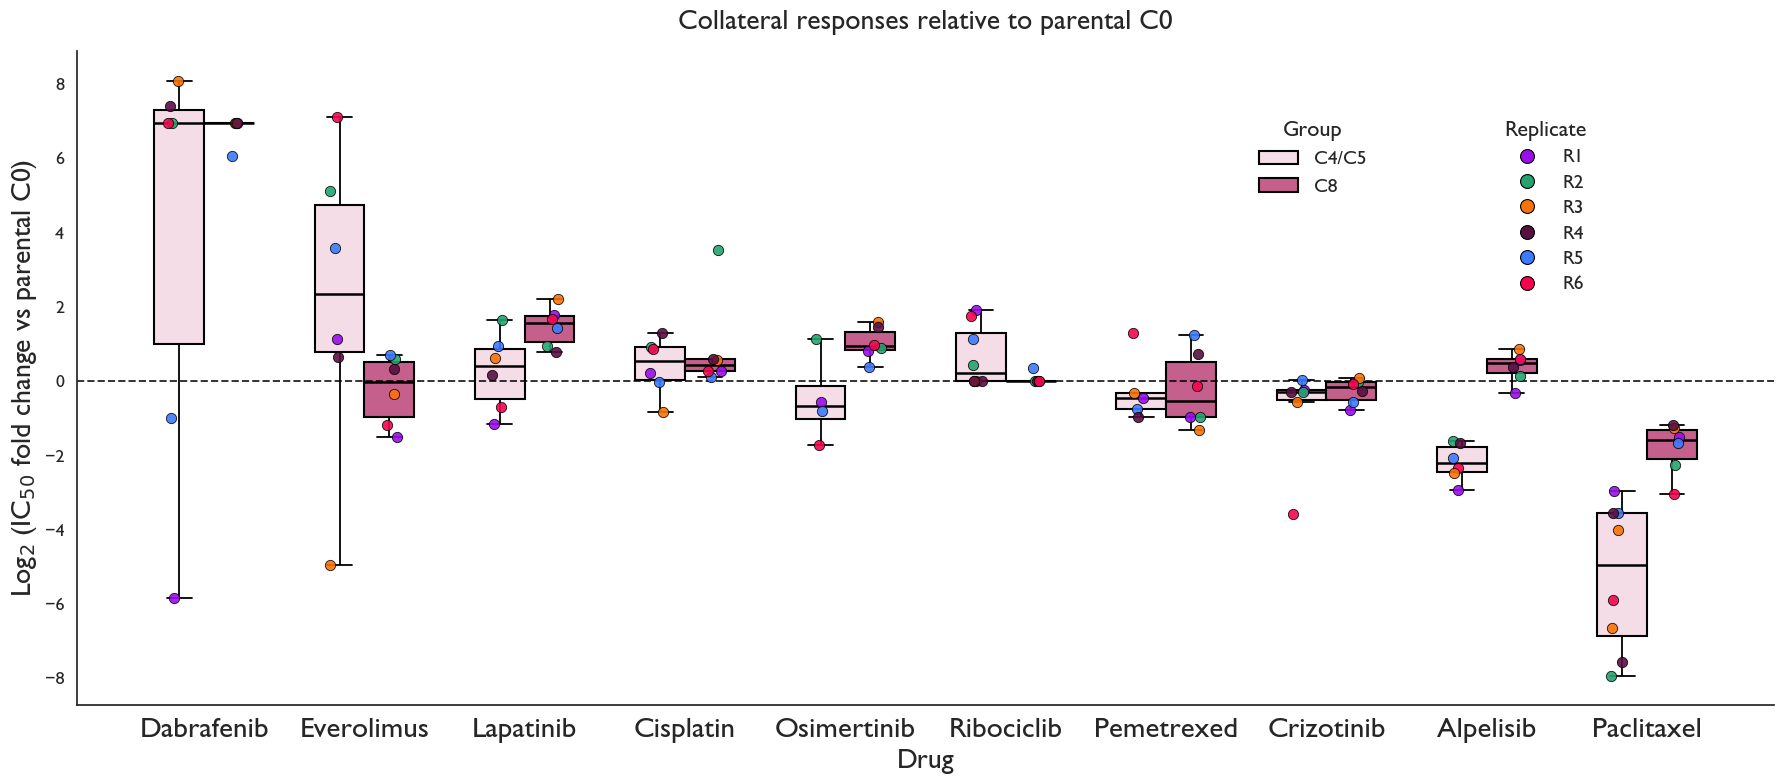

In [10]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# 1. Selection and plotting settings
# ============================================================

waterfall_selection = {
    "osimertinib": {
        4: ["R1-m", "R2-m", "R5-m", "R6-m"],
        8: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"]
    },

    "lapatinib": {
        4: ["R1-m", "R2-m", "R5-m", "R6-m"],
        5: ["R3-m", "R4-m"],
        8: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"]
    },

    "crizotinib": {
        4: ["R1-m", "R2-m", "R5-m", "R6-m"],
        5: ["R3-m", "R4-m"],
        8: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"]
    },

    "alpelisib": {
        4: ["R1-m", "R2-m", "R5-m", "R6-m"],
        5: ["R3-m", "R4-m"],
        8: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"]
    },

    "dabrafenib": {
        4: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"],
        8: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m"]
    },

    "everolimus": {
        4: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"],
        8: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"]
    },

    "ribociclib": {
        4: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"],
        5: ["R3-m", "R4-m"],
        8: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"]
    },

    "paclitaxel": {
        4: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"],
        5: ["R3-m", "R4-m"],
        8: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"]
    },

    "cisplatin": {
        4: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"],
        8: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"]
    },

    "pemetrexed": {
        4: ["R1-m", "R5-m", "R6-m"],
        5: ["R3-m", "R4-m"],
        8: ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"]
    }
}

group_order = ["C4/C5", "C8"]

# lighter pink -> darker pink
group_palette = {
    "C4/C5": "#f8d9e6",
    "C8": "#d64f8a"
}

figure_dir = os.path.join(data_dir, "figures")
os.makedirs(figure_dir, exist_ok=True)


# ============================================================
# 2. Build waterfall dataframe
# ============================================================

waterfall_rows = []

for drug_name, cycle_dict in waterfall_selection.items():

    # --------------------------------------------------------
    # Parental C0 IC50 reference
    # Use D1-m C0 only
    # --------------------------------------------------------
    c0_values = params_df_bootstraps.loc[
        (params_df_bootstraps["Drug"] == drug_name) &
        (params_df_bootstraps["Parameter"] == "ic50") &
        (params_df_bootstraps["CycleId"] == 0) &
        (params_df_bootstraps["ReplicateName"] == "D1-m"),
        "Value"
    ].dropna()

    c0_values = c0_values[c0_values > 0]

    if c0_values.empty:
        print(f"Missing parental C0 IC50 for {drug_name}")
        continue

    c0_median = c0_values.median()

    # --------------------------------------------------------
    # Resistant replicate IC50 values
    # --------------------------------------------------------
    for cycle_id, replicate_list in cycle_dict.items():

        if cycle_id in [4, 5]:
            cycle_group = "C4/C5"
        elif cycle_id == 8:
            cycle_group = "C8"
        else:
            continue

        for replicate_name in replicate_list:

            curr_values = params_df_bootstraps.loc[
                (params_df_bootstraps["Drug"] == drug_name) &
                (params_df_bootstraps["Parameter"] == "ic50") &
                (params_df_bootstraps["CycleId"] == cycle_id) &
                (params_df_bootstraps["ReplicateName"] == replicate_name),
                "Value"
            ].dropna()

            curr_values = curr_values[curr_values > 0]

            if curr_values.empty:
                print(
                    f"Missing IC50: {drug_name}, "
                    f"C{cycle_id}, {replicate_name}"
                )
                continue

            curr_median = curr_values.median()

            fold_change = curr_median / c0_median
            log2_fc = np.log2(fold_change)

            waterfall_rows.append(
                {
                    "Drug": drug_name,
                    "CycleId": cycle_id,
                    "CycleGroup": cycle_group,
                    "ReplicateName": replicate_name,
                    "IC50": curr_median,
                    "Parental_C0_IC50": c0_median,
                    "FoldChange": fold_change,
                    "log2_FoldChange": log2_fc
                }
            )

waterfall_df = pd.DataFrame(waterfall_rows)


# ============================================================
# 3. QC
# ============================================================

display(
    waterfall_df.sort_values(
        ["Drug", "CycleGroup", "CycleId", "ReplicateName"]
    )
)

print("\nNumber of included points per drug/group:")

display(
    waterfall_df
    .groupby(["Drug", "CycleGroup"])
    .size()
    .rename("N")
    .reset_index()
)


# ============================================================
# 4. Rank drugs from most resistant to most sensitive
# ============================================================

drug_order = (
    waterfall_df
    .groupby("Drug")["log2_FoldChange"]
    .mean()
    .sort_values(ascending=False)
    .index
    .tolist()
)

print("Drug order: most resistant -> most sensitive")
print(drug_order)


# ============================================================
# 5. Plot
# ============================================================

fig, ax = plt.subplots(figsize=(18, 8))


# ------------------------------------------------------------
# Boxplots
# ------------------------------------------------------------
sns.boxplot(
    data=waterfall_df,
    x="Drug",
    y="log2_FoldChange",
    hue="CycleGroup",
    order=drug_order,
    hue_order=group_order,
    palette=group_palette,
    width=0.62,
    dodge=True,
    showcaps=True,
    showfliers=False,
    boxprops={
        "edgecolor": "black",
        "linewidth": 1.5
    },
    whiskerprops={
        "color": "black",
        "linewidth": 1.3
    },
    capprops={
        "color": "black",
        "linewidth": 1.3
    },
    medianprops={
        "color": "black",
        "linewidth": 1.8
    },
    ax=ax
)


# ------------------------------------------------------------
# Overlay individual replicate points
# ------------------------------------------------------------
offset_map = {
    "C4/C5": -0.18,
    "C8": 0.18
}

rng = np.random.default_rng(42)

for _, row in waterfall_df.iterrows():

    x_base = drug_order.index(row["Drug"])

    x_pos = (
        x_base
        + offset_map[row["CycleGroup"]]
        + rng.uniform(-0.045, 0.045)
    )

    ax.scatter(
        x_pos,
        row["log2_FoldChange"],
        s=55,
        color=replicate_palette[row["ReplicateName"]],
        edgecolor="black",
        linewidth=0.6,
        alpha=0.90,
        zorder=5
    )


# ------------------------------------------------------------
# Reference line: no change vs C0
# ------------------------------------------------------------
ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.4,
    alpha=0.8
)


# ============================================================
# 6. Formatting
# ============================================================

ax.set_title(
    "Collateral responses relative to parental C0",
    fontsize=20,
    pad=16
)

ax.set_xlabel(
    "Drug",
    fontsize=20
)

ax.set_ylabel(
    r"Log$_2$ (IC$_{50}$ fold change vs parental C0)",
    fontsize=20
)

ax.set_xticks(range(len(drug_order)))

ax.set_xticklabels(
    [drug.capitalize() for drug in drug_order],
    ha="center",
    fontsize=21
)

ax.tick_params(
    axis="y",
    labelsize=13
)


# ============================================================
# 7. Group legend
# ============================================================

handles, labels = ax.get_legend_handles_labels()

group_legend = ax.legend(
    handles[:2],
    labels[:2],
    title="Group",
    frameon=False,
    fontsize=14,
    title_fontsize=16,
    loc="upper right",
    bbox_to_anchor=(0.77, 0.92)
)

# Important: keep this legend when adding second legend
ax.add_artist(group_legend)


# ============================================================
# 8. Replicate color legend
# ============================================================

replicate_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=replicate_palette["R1-m"],
        markeredgecolor="black",
        markeredgewidth=0.8,
        markersize=10,
        label="R1"
    ),

    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=replicate_palette["R2-m"],
        markeredgecolor="black",
        markeredgewidth=0.8,
        markersize=10,
        label="R2"
    ),

    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=replicate_palette["R3-m"],
        markeredgecolor="black",
        markeredgewidth=0.8,
        markersize=10,
        label="R3"
    ),

    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=replicate_palette["R4-m"],
        markeredgecolor="black",
        markeredgewidth=0.8,
        markersize=10,
        label="R4"
    ),

    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=replicate_palette["R5-m"],
        markeredgecolor="black",
        markeredgewidth=0.8,
        markersize=10,
        label="R5"
    ),

    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=replicate_palette["R6-m"],
        markeredgecolor="black",
        markeredgewidth=0.8,
        markersize=10,
        label="R6"
    )
]

ax.legend(
    handles=replicate_handles,
    title="Replicate",
    frameon=False,
    fontsize=14,
    title_fontsize=16,
    loc="upper right",
    bbox_to_anchor=(0.90, 0.92),
    labelspacing=0.4
)


# ------------------------------------------------------------
# Appearance
# ------------------------------------------------------------
sns.despine()
plt.tight_layout()


# ============================================================
# 9. Save
# ============================================================

plt.savefig(
    os.path.join(
        figure_dir,
        "CS_waterfall_C45_vs_C8_relative_to_C0_ranked_3.pdf"
    ),
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "CS_waterfall_C45_vs_C8_relative_to_C0_ranked_3.png"
    ),
    dpi=1200,
    bbox_inches="tight"
)

plt.show()